# Foundations: from Maxwell's equations to pyoptics, and its conventions

Every module of pyoptics solves Maxwell's equations, but almost none of them
solves them *as such*. Each works on one rung of a ladder of approximations:
time harmonic fields, the Helmholtz equation, the angular spectrum of plane
waves, the Fresnel and Fraunhofer integrals, and on another branch the
eikonal, rays and paraxial matrices. Knowing which rung a module stands on
tells you what it can and cannot describe. And because every rung inherits
the signs of the one above it, knowing the **conventions** (sign of the time
dependence, the Fourier transform, signs of radii and angles, the pupil
phase, handedness of circular polarization) is what makes results of
different modules fit together.

This notebook walks down the ladder once. At every step it states the
equations in the form pyoptics uses, names the modules that work there, and
*checks the conventions numerically against the code*, against analytic
results, or against another module on a neighbouring rung:

1. **The map**: the levels of approximation and the modules that work on each.
2. **Maxwell's equations and the time convention** exp(−iωt): a 1D FDTD run
   shows that its complex amplitudes go as exp(+ikx), and how a phasor
   becomes a real field.
3. **Wave equation, Helmholtz equation and plane waves**: the dispersion
   relation, and evanescent waves on the branch Im k_z ≥ 0.
4. **The Fourier convention** of `pyoptics.fft`: the kernel sign, centring,
   wavenumbers vs. frequencies and the scaling to the continuous transform.
5. **Green's function and diffraction**: Rayleigh-Sommerfeld (= angular
   spectrum), Fresnel and Fraunhofer for a circular hole against the exact
   on-axis formula and the Airy pattern, over the Fresnel number.
6. **The paraxial wave equation and Gaussian beams**: sign of the wavefront
   curvature and of the Gouy phase, analytic vs. propagated.
7. **Eikonal and rays**: rays as normals of the wavefronts of a computed
   field, the sign conventions of the ray tracer, and the chain
   ray-traced OPD → pupil phase → PSF → angular spectrum, closing to
   rounding error.
8. **Interfaces**: the Fresnel coefficients and their two sign conventions.
9. **Polarization**: Jones vectors, which way [1, i] turns, Stokes S₃, wave
   plates and rotated elements.
10. **Pupils and Zernikes**: Fringe ordering, normalization, the azimuth and
    the sign of defocus.
11. **Arrays, axes and units** of the different modules.
12. **Cheat sheet** of all conventions, and the **inconsistencies** found
    while writing this notebook.

The conventions are also listed on the documentation page *Conventions*
(`docs/conventions.md`); this notebook shows where each comes from and
tests it.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.special import j1

from pyoptics import sketch, fdtd, beams, imaging, interfaces, thin_films, masks
from pyoptics import raytrace as rt
from pyoptics.bases import fringe_zernike, fringe_to_n_m, fringe_zernike_norm
from pyoptics.fft import FT, inv_FT
from pyoptics.polarization import jones, mueller
from pyoptics.propagators import (rayleigh_sommerfeld_I_TF, rayleigh_sommerfeld_I_TF_planes,
                                  fresnel_TF, fraunhofer_scaled, propagate_padded)
from pyoptics.utils import grid1d, grid2d, frequencies, freq_grid, k_z

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "image.origin": "lower"})
BLUE, RED, GREEN, ORANGE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "0.45"
t_start = time.time()

## 1. The map

Maxwell's equations sit at the top. Each arrow below is an assumption, and
each box is the equation that remains, with the pyoptics modules that solve
it. Going down, the models become cheaper and lose physics: the FDTD
(`fdtd`) handles any structure, pulses and all, but needs a grid finer than
the wavelength in all dimensions; the scalar angular spectrum
(`propagators`) is exact in a homogeneous medium and needs only a 2D grid;
Fraunhofer diffraction is one FFT; a paraxial ray is a 2 × 2 matrix.

Two side branches are exact under their own assumptions rather than
approximations. **Planar interfaces and layers** (`interfaces`,
`thin_films`, `coatings`) solve Maxwell's equations exactly for plane waves
on piecewise constant, planar media. **Polarization** (`polarization`)
describes the two transverse components of a plane wave (or of a ray) by a
Jones vector, and partially polarized light by a Stokes vector.

The two dashed arrows are the bridges between waves and rays: the ray picture
is the stationary phase limit of the wave integrals (`raywave` builds waves
from rays), and the ABCD matrices of paraxial rays also propagate the complex
beam parameter q of Gaussian beams.

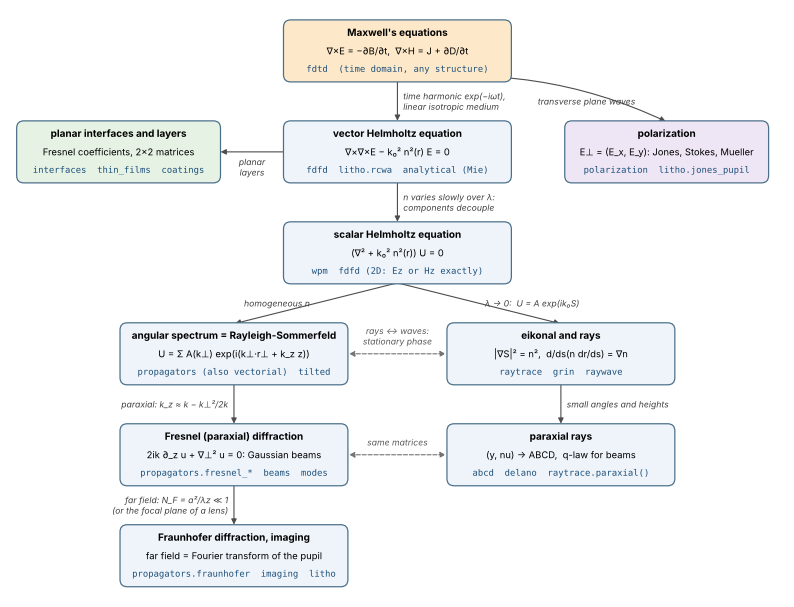

In [2]:
fig, ax = plt.subplots(figsize=(15, 9.6))
sketch.approximation_map(ax)
plt.show()

## 2. Maxwell's equations and the time convention

In a linear, isotropic, non-magnetic medium without free charges, Maxwell's
equations read

$$
\nabla\times\mathbf E = -\mu_0\,\partial_t \mathbf H,\qquad
\nabla\times\mathbf H = \mathbf J + \partial_t(\varepsilon\mathbf E),\qquad
\nabla\cdot(\varepsilon\mathbf E) = 0,\qquad \nabla\cdot\mathbf H = 0 .
$$

The FDTD (`pyoptics.fdtd`) integrates exactly these equations in time, in
normalized units ($c = \varepsilon_0 = \mu_0 = 1$, lengths and wavelengths
in the same unit, times in that unit over $c$).

Everything else in pyoptics works at a single frequency. A monochromatic
field is written as the real part of a complex amplitude (a phasor) times a
time factor, and **pyoptics uses**

$$
\mathbf E(\mathbf r, t) = \mathrm{Re}\{\mathbf E(\mathbf r)\,e^{-i\omega t}\},
$$

the convention of physics texts (Born & Wolf, Jackson, Goodman, Zangwill).
The time factor is never written in the code. With it, $\partial_t \to
-i\omega$, a plane wave travelling in $+\hat{\mathbf k}$ is
$e^{+i\mathbf k\cdot\mathbf r}$, a wave grows in phase as it travels, an
outgoing spherical wave is $e^{+ikr}/r$, and an absorbing medium has the
complex refractive index $n + i\kappa$ with $\kappa > 0$, so that
$e^{ik_0(n + i\kappa)z}$ decays.

Engineering texts (and McLeod's thin films, Siegman's *Lasers*) use
$e^{+j\omega t}$. Their formulas turn into ours by complex conjugation:
$j \to -i$, $e^{-jkz} \to e^{+ikz}$, $n - jk \to n + i\kappa$.

**Check with the FDTD.** The FDTD itself is real; its DFT monitors return
complex amplitudes $F = \sum_t f(t)\,e^{+i\omega t}\,\Delta t$, which is the
phasor of the $e^{-i\omega t}$ convention. A continuous wave source at
$x = -3$ radiates to both sides; a glass block ($n = 1.5$) from $x = 2$
reaches into the absorbing boundary, so there is no back reflection from
its end. The unwrapped phase of the phasor must rise with slope $+k_0$ to
the right of the source, $+nk_0$ in the glass, and fall with $-k_0$ to its
left, where the wave travels in $-x$.

phase slope x < −3 (towards −x)   :  -6.2832, expected  -6.2832 (rel. diff. 8.5e-06)
phase slope −3 < x < 2 (air)      :  +6.2668, expected  +6.2832 (rel. diff. -2.6e-03)
phase slope 2 < x (glass)         :  +9.4372, expected  +9.4248 (rel. diff. 1.3e-03)
max |Re{E e^(-iwt)} - E(t)| at the probe over the last periods: 2.9e-04 (field amplitude 0.40)


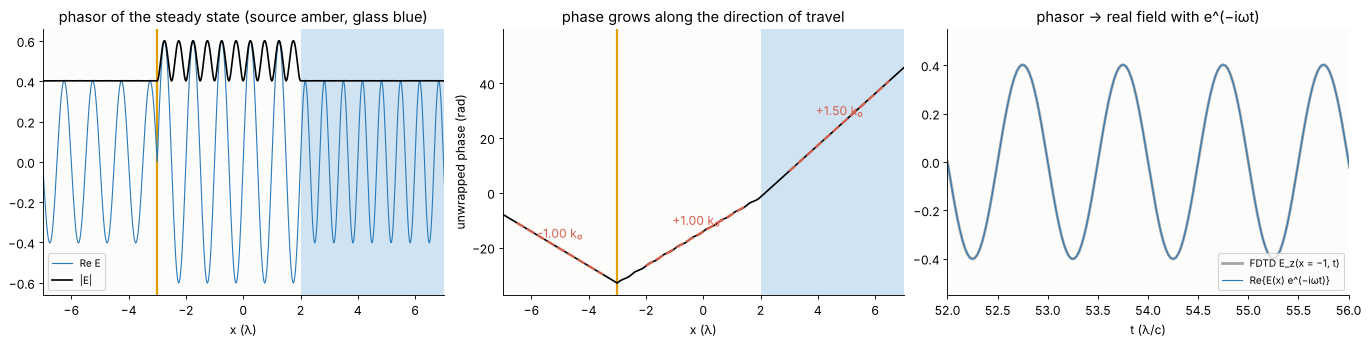

In [3]:
WL = 1.0
k0 = 2*np.pi/WL
grid = fdtd.Grid(16.0, WL/40)
probe = fdtd.Probe(-1.0)
dft = fdtd.DFTField(WL, start=30.0)
sim = fdtd.Simulation(grid, [(fdtd.Slab(2.0, 10.0), fdtd.Medium.from_index(1.5))],
                      sources=[fdtd.PointSource(-3.0, fdtd.ContinuousWave(WL))],
                      monitors=[dft, probe], boundaries=fdtd.PML(40))
sim.run(time=60.0)
E = dft.steady_state("Ez")[0]          # phasor of the steady state
x, = dft.coords("Ez")
phase = np.unwrap(np.angle(E))

fits = []
for (lo, hi), expected, name in (((-6.5, -3.5), -k0, "x < −3 (towards −x)"),
                                 ((-2.0, 1.5), k0, "−3 < x < 2 (air)"),
                                 ((3.0, 6.5), 1.5*k0, "2 < x (glass)")):
    m = (x > lo) & (x < hi)
    slope = np.polyfit(x[m], phase[m], 1)[0]
    fits.append((lo, hi, slope))
    print("phase slope {:22s}: {:+8.4f}, expected {:+8.4f} (rel. diff. {:.1e})".format(
        name, slope, expected, slope/expected - 1))

# the phasor at the probe against the recorded real field
xp = x[np.argmin(np.abs(x + 1.0))]
t = probe.times
recon = np.real(E[np.argmin(np.abs(x - xp))]*np.exp(-1j*k0*t))   # omega = k0 for c = 1
late = t > 50
print("max |Re{{E e^(-iwt)}} - E(t)| at the probe over the last periods: {:.1e} (field amplitude {:.2f})".format(
    np.max(np.abs(recon[late] - probe.values[late])), np.abs(E[np.argmin(np.abs(x - xp))])))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2), layout="constrained")
for a in ax[:2]:
    a.axvspan(2.0, 8.0, color="#cfe3f3", lw=0)
    a.axvline(-3.0, color=ORANGE, lw=2)
ax[0].plot(x, E.real, color=BLUE, lw=1, label="Re E")
ax[0].plot(x, np.abs(E), color="k", lw=1.5, label="|E|")
ax[0].set_xlim(-7, 7)
ax[0].set_xlabel("x (λ)")
ax[0].set_title("phasor of the steady state (source amber, glass blue)")
ax[0].legend(loc="lower left", fontsize=9)
ax[1].plot(x, phase, color="k", lw=1.5)
for lo, hi, s in fits:
    xx = np.linspace(lo, hi, 2)
    m = (x > lo) & (x < hi)
    ax[1].plot(xx, np.polyval(np.polyfit(x[m], phase[m], 1), xx), "--", color=RED, lw=2)
    ax[1].text((lo + hi)/2, np.polyval(np.polyfit(x[m], phase[m], 1), (lo + hi)/2) + 4,
               "{:+.2f} k₀".format(s/k0), ha="center", color=RED)
ax[1].set_xlim(-7, 7)
ax[1].set_xlabel("x (λ)")
ax[1].set_ylabel("unwrapped phase (rad)")
ax[1].set_title("phase grows along the direction of travel")
ax[2].plot(t, probe.values, color="k", lw=2.5, alpha=0.35, label="FDTD E_z(x = −1, t)")
ax[2].plot(t, recon, color=BLUE, lw=1, label="Re{E(x) e^(−iωt)}")
ax[2].set_xlim(52, 56)
ax[2].set_xlabel("t (λ/c)")
ax[2].set_title("phasor → real field with e^(−iωt)")
ax[2].legend(loc="lower right", fontsize=9)
plt.show()

The slopes agree with $-k_0$, $+k_0$ and $+1.5\,k_0$ to a few $10^{-3}$:
the remaining difference is the numerical dispersion of the Yee grid (40
cells per wavelength in air, 27 in the glass), and between source and glass
the wave reflected at the glass ($r = -0.2$) runs back and makes the
amplitude and the phase ripple. The phasor at the probe reproduces the recorded real field when
multiplied by $e^{-i\omega t}$, not by $e^{+i\omega t}$.

Two consequences used throughout pyoptics:

- **A positive phase is a delay.** The phase grows along the direction of
  travel, and a point further from the source sees the same crest later. At
  a fixed point, $\mathrm{Re}\{e^{i\varphi}e^{-i\omega t}\} =
  \cos(\omega t - \varphi)$ peaks at $t = \varphi/\omega$: a field with
  the extra phase $\varphi > 0$ arrives *later*. More optical path (glass, a
  detour, a wavefront that lags behind a reference) means a larger phase,
  $\varphi = k_0 \cdot \mathrm{OPL}$. Section 7 shows how this fixes the sign
  of the pupil phase of the ray tracer.
- In the frequency domain, signals in **time** are synthesized with
  $e^{-i\omega t}$ but fields in **space** with $e^{+i\mathbf k\cdot\mathbf
  r}$. Time and space Fourier transforms thus have *opposite* signs
  (`pyoptics.ultrafast`: $E(t) = \sum E(\omega)\,e^{-i(\omega -
  \omega_0)t}\,\Delta\omega/2\pi$; `pyoptics.fft.inv_FT`: kernel $e^{+ik_x
  x}$).

## 3. Wave equation, Helmholtz equation and plane waves

Taking the curl of Faraday's law and using the other equations gives, for a
medium with $\varepsilon(\mathbf r) = \varepsilon_0 n^2(\mathbf r)$,

$$
\nabla\times\nabla\times\mathbf E - \frac{n^2}{c^2}\,\partial_t^2\mathbf E = 0
\quad\xrightarrow{\;e^{-i\omega t}\;}\quad
\nabla\times\nabla\times\mathbf E - k_0^2 n^2\,\mathbf E = 0,
\qquad k_0 = \frac{\omega}{c} = \frac{2\pi}{\lambda_0}.
$$

This **vector Helmholtz equation** is what the FDFD (`fdfd`), the RCWA
(`litho.rcwa`) and the Mie series (`analytical`) solve. With
$\nabla\times\nabla\times = \nabla(\nabla\cdot) - \nabla^2$ and
$\nabla\cdot\mathbf E = -\mathbf E\cdot\nabla \ln n^2$, the components
couple only through the gradient of the index. Where $n$ changes little over
a wavelength (or not at all), each Cartesian component obeys the **scalar
Helmholtz equation**

$$
\left(\nabla^2 + k_0^2 n^2(\mathbf r)\right) U = 0 .
$$

The wave propagation method (`wpm`) solves it in a slowly varying medium. In
2D, for fields invariant along z, the component $E_z$ obeys it *exactly*
also for abrupt index changes (the FDTD/FDFD mode `"Ez"`).

**Plane waves.** In a homogeneous medium, $U = e^{i(k_x x + k_y y + k_z
z)}$ solves the Helmholtz equation if $k_x^2 + k_y^2 + k_z^2 = k^2 = n^2
k_0^2$. For a given transverse wave vector,

$$
k_z = \sqrt{k^2 - k_x^2 - k_y^2}, \qquad \text{branch with } \mathrm{Im}\,k_z \ge 0 .
$$

For $k_\perp < k$ the wave propagates at the angle $\sin\theta = k_\perp/k$;
for $k_\perp > k$ it is **evanescent**, $k_z = +i\sqrt{k_\perp^2 - k^2}$,
and decays as $e^{-|k_z| z}$ in $+z$. `utils.k_z()` returns this branch (also
for complex $k$ in absorbing media), and all propagators use it.

k_z(0.6 k) = 0.8000 k,   k_z(1.3 k) = 0.8307i k   (Im k_z >= 0 everywhere: True)


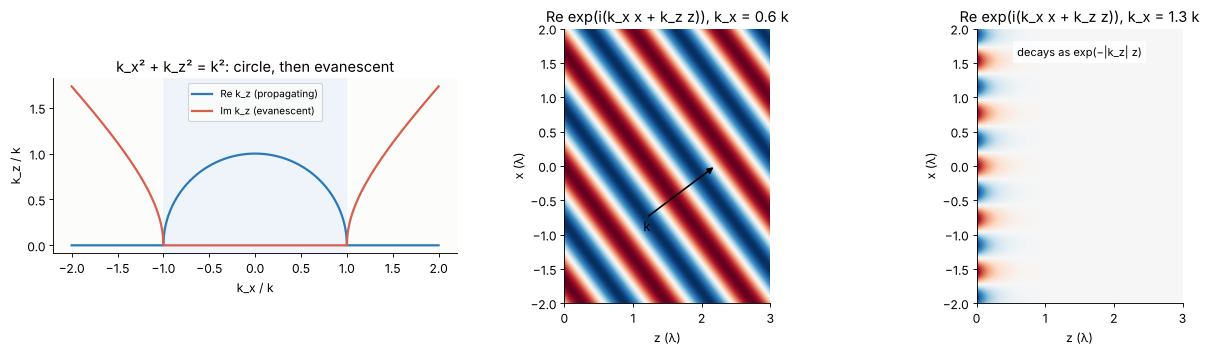

In [4]:
k = 2*np.pi                                   # lambda = 1
kx = np.linspace(-2.0, 2.0, 801)*k
kz = k_z(k, kx, 0.0)
print("k_z(0.6 k) = {:.4f} k,   k_z(1.3 k) = {:.4f}i k   (Im k_z >= 0 everywhere: {})".format(
    k_z(k, 0.6*k, 0.0)/k, (k_z(k, 1.3*k, 0.0)/k).imag, bool(np.all(kz.imag >= 0))))

xx = np.linspace(-2, 2, 400)
zz = np.linspace(0, 3, 300)
XX, ZZ = np.meshgrid(xx, zz, indexing="xy")
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3), layout="constrained")
ax[0].plot(kx/k, kz.real/k, color=BLUE, lw=2, label="Re k_z (propagating)")
ax[0].plot(kx/k, kz.imag/k, color=RED, lw=2, label="Im k_z (evanescent)")
ax[0].axvspan(-1, 1, color="#eef4fa", lw=0)
ax[0].set_xlabel("k_x / k")
ax[0].set_ylabel("k_z / k")
ax[0].set_title("k_x² + k_z² = k²: circle, then evanescent")
ax[0].legend(fontsize=9)
ax[0].set_aspect("equal")
for a, f in zip(ax[1:], (0.6, 1.3)):
    kzf = k_z(k, f*k, 0.0)
    U = np.exp(1j*(f*k*XX + kzf*ZZ))
    a.imshow(U.real.T, extent=(zz[0], zz[-1], xx[0], xx[-1]), cmap="RdBu_r", vmin=-1, vmax=1)
    a.set_xlabel("z (λ)")
    a.set_ylabel("x (λ)")
    a.set_title("Re exp(i(k_x x + k_z z)), k_x = {:.1f} k".format(f))
ax[1].annotate("", xy=(2.2, 0.0), xytext=(1.2, -0.75),
               arrowprops=dict(arrowstyle="-|>", color="k", lw=1.5))
ax[1].text(1.15, -0.95, "k", fontsize=12)
ax[2].text(1.5, 1.6, "decays as exp(−|k_z| z)", ha="center", fontsize=10,
           bbox=dict(facecolor="white", edgecolor="none", alpha=0.8))
plt.show()

The evanescent wave keeps its period along x, but its amplitude falls by
$e^{-2\pi\sqrt{1.3^2 - 1}} \approx 0.4\,\%$ per wavelength in z. The images
show z horizontally, as all sketches and ray plots of pyoptics do; arrays of
the wave optics modules are indexed `[y, x]` (section 11).

## 4. The Fourier convention

A field in a plane is a superposition of plane waves (its **angular
spectrum**). `pyoptics.fft` defines the pair

$$
\mathrm{FT}(f)(k_x, k_y) = \sum_{x, y} f(x, y)\, e^{-i(k_x x + k_y y)},
\qquad
\mathrm{inv\_FT}(F)(x, y) = \frac{1}{N_x N_y}\sum_{k_x, k_y} F(k_x, k_y)\, e^{+i(k_x x + k_y y)},
$$

so that `FT()` returns the amplitudes of the plane waves $e^{+i(k_x x + k_y
y)}$ that `inv_FT()` adds up, consistent with $e^{-i\omega t}$: a component
with $k_x > 0$ travels towards $+x$.

- **Centred arrays.** Both take and return arrays with $x = 0$ at index
  $N/2$ and $k = 0$ at index $N/2$ (`fftshift` order).
  `utils.grid1d(-L/2, L/2, N)` and `utils.grid2d()` give such coordinates
  for even N (the right end point is left out, as for a periodic signal),
  and `utils.frequencies(x)` / `utils.freq_grid(x, y)` the matching
  frequencies.
- **Wavenumbers or frequencies.** `frequencies(x)` returns *angular*
  wavenumbers $k = 2\pi f$ (rad per length unit) by default, and the spatial
  frequencies $f$ (cycles per length unit) with `wavenumbers=False`. The
  spacing of $k$ is $2\pi/L$; its range is $\pm\pi/\Delta x$.
- **Scaling.** Like `numpy.fft`, `FT()` is not normalized: `FT(f)*dx*dy`
  approximates the continuous integral $\int f\,e^{-i\mathbf k\cdot\mathbf
  r}\,d^2r$. `FT_unitary()` conserves $\sum|f|^2$.

**Checks:** the spectrum of $e^{+ik_0 x}$ must peak at $+k_0$; a Gaussian
$e^{-r^2/(2\sigma^2)}$ shifted to $x_0$ must give $2\pi\sigma^2 e^{-k^2\sigma^2/2}
e^{-ik_x x_0}$, a phase that *falls* along $k_x$ with the slope $-x_0$.

x = 0 at index 128 of 256 ; k = 0 at index 128 ; dk = 2 pi/L: True
plane wave exp(+i k0 x), k0 = 3.1416: spectrum peaks at k_x = +3.1416, k_y = +0.0000
Gaussian: max |FT*dx*dy - analytic| / max = 2.5e-16
inv_FT(FT(g)) == g: 2.3e-16


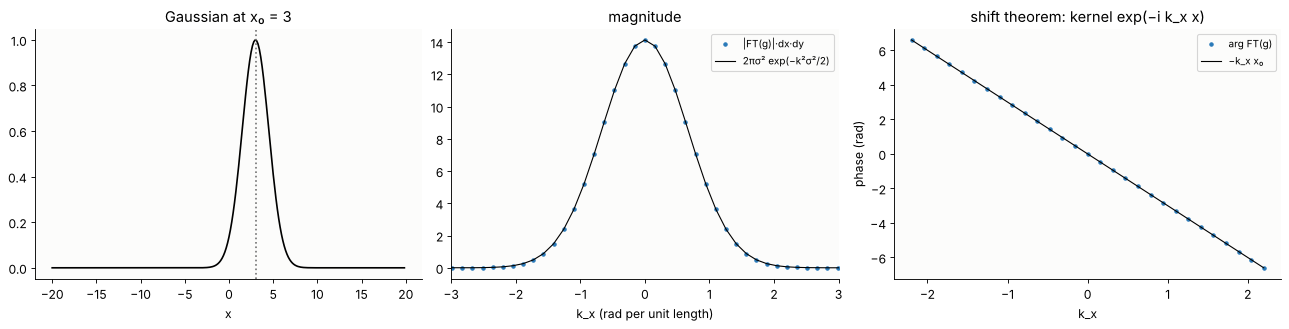

In [5]:
L, N = 40.0, 256
x, y, X, Y = grid2d(-L/2, L/2, -L/2, L/2, N)
dx = x[1] - x[0]
kxs = frequencies(x)                                  # angular wavenumbers, centred
KX, KY = freq_grid(x, y)                              # wavenumbers=True, normal_order=True
print("x = 0 at index", np.argmin(np.abs(x)), "of", N, "; k = 0 at index", np.argmin(np.abs(kxs)),
      "; dk = 2 pi/L:", np.isclose(kxs[1] - kxs[0], 2*np.pi/L))

k_tilt = kxs[N//2 + 20]
F = FT(np.exp(1j*k_tilt*X))
iy, ix = np.unravel_index(np.argmax(np.abs(F)), F.shape)
print("plane wave exp(+i k0 x), k0 = {:.4f}: spectrum peaks at k_x = {:+.4f}, k_y = {:+.4f}".format(
      k_tilt, KX[iy, ix], KY[iy, ix]))

sigma, x0 = 1.5, 3.0
g = np.exp(-((X - x0)**2 + Y**2)/(2*sigma**2))
G_num = FT(g)*dx*dx
G_ana = 2*np.pi*sigma**2*np.exp(-(KX**2 + KY**2)*sigma**2/2)*np.exp(-1j*KX*x0)
print("Gaussian: max |FT*dx*dy - analytic| / max = {:.1e}".format(
      np.max(np.abs(G_num - G_ana))/np.max(np.abs(G_ana))))
print("inv_FT(FT(g)) == g: {:.1e}".format(np.max(np.abs(inv_FT(FT(g)) - g))))

fig, ax = plt.subplots(1, 3, figsize=(16, 4.0), layout="constrained")
ax[0].plot(x, g[N//2], color="k", lw=1.5)
ax[0].axvline(x0, color=GREY, ls=":")
ax[0].set_xlabel("x")
ax[0].set_title("Gaussian at x₀ = {:.0f}".format(x0))
ax[1].plot(kxs, np.abs(G_num[N//2]), "o", color=BLUE, ms=3, label="|FT(g)|·dx·dy")
ax[1].plot(kxs, np.abs(G_ana[N//2]), color="k", lw=1, label="2πσ² exp(−k²σ²/2)")
ax[1].set_xlim(-3, 3)
ax[1].set_xlabel("k_x (rad per unit length)")
ax[1].legend(fontsize=9)
ax[1].set_title("magnitude")
m = np.abs(kxs) < 2.2
ph_num = np.unwrap(np.angle(G_num[N//2, m]))
ph_num -= ph_num[np.argmin(np.abs(kxs[m]))]           # phase 0 at k_x = 0 (removes a 2 pi multiple)
ax[2].plot(kxs[m], ph_num, "o", color=BLUE, ms=3, label="arg FT(g)")
ax[2].plot(kxs[m], -kxs[m]*x0, color="k", lw=1, label="−k_x x₀")
ax[2].set_xlabel("k_x")
ax[2].set_ylabel("phase (rad)")
ax[2].set_title("shift theorem: kernel exp(−i k_x x)")
ax[2].legend(fontsize=9)
plt.show()

## 5. Green's function and diffraction

The outgoing Green's function of the Helmholtz operator,
$(\nabla^2 + k^2)\,G = -\delta(\mathbf r)$, is the spherical wave

$$
G(\mathbf r) = \frac{e^{+ikr}}{4\pi r}
$$

(outgoing *because* of $e^{-i\omega t}$; `beams.spherical_wave()` returns
$e^{+ikR}/R$ for $z > z_0$). Green's theorem with a Green's function that
vanishes on the plane $z = 0$ gives the **Rayleigh-Sommerfeld integral of the
first kind**: the field behind a plane is a sum of secondary wavelets from
every point of the plane,

$$
U(x, y, z) = \frac{1}{2\pi}\int U(x', y', 0)\, \frac{z}{r}\left(\frac{1}{r} - ik\right)\frac{e^{ikr}}{r}\,dx'dy'
\;\approx\; \frac{1}{i\lambda}\int U(x', y', 0)\,\cos\theta\,\frac{e^{ikr}}{r}\,dx'dy' \quad (kr\gg 1).
$$

Its Fourier transform along x and y is exactly the transfer function
$e^{ik_z z}$ of the angular spectrum: **Rayleigh-Sommerfeld I and the angular
spectrum method are the same solution** of the Helmholtz equation in the half
space $z > 0$, without further approximation
(`propagators.rayleigh_sommerfeld_I_TF()`, `..._IR()`, `..._DI()`).

Expanding $r$ for small angles, $r \approx z + [(x - x')^2 + (y - y')^2]/(2z)$,
gives the **Fresnel integral** (`propagators.fresnel_TF()`, `fresnel_IR()`,
`fresnel_scaled()`), the paraxial transfer function $e^{ikz}e^{-iz
k_\perp^2/(2k)}$. Far away, where the aperture of radius $a$ holds much less
than one Fresnel zone ($N_F = a^2/(\lambda z) \ll 1$), the quadratic phase over
the aperture drops out and the field is the Fourier transform of the aperture
field, the **Fraunhofer integral** (`propagators.fraunhofer()`,
`fraunhofer_scaled()`, and `imaging`, where a lens brings the far field into
its focal plane).

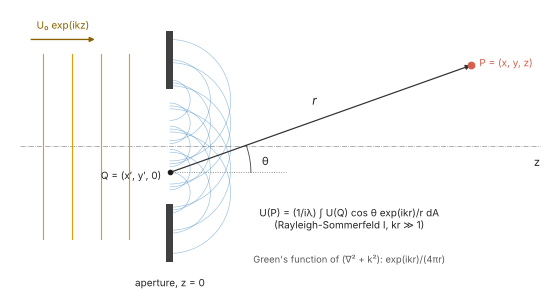

In [6]:
fig, ax = plt.subplots(figsize=(11, 4.6))
sketch.diffraction_geometry(ax)
plt.show()

**Check: a circular hole.** On the axis behind a hole of radius $a$ lit by a
plane wave, the Rayleigh-Sommerfeld integral is elementary,

$$
U(0, 0, z) = e^{ikz} - \frac{z}{\sqrt{z^2 + a^2}}\,e^{ik\sqrt{z^2 + a^2}},
$$

the direct wave minus an edge wave. The Fresnel approximation turns this
into $|U|^2 = 4\sin^2(\pi N_F/2)$: the axis is bright for an odd and dark
for an even number of Fresnel zones in the hole. Both are compared with the
angular spectrum (`rayleigh_sommerfeld_I_TF_planes()`, band limited for the
far planes) and the Fresnel transfer function (`fresnel_TF()`, zero padded
by `propagate_padded()`) of a hole of
radius $16\lambda$, sampled at $\lambda/4$ with area weighted edge pixels.

In [7]:
WL, a = 1.0, 16.0
k = 2*np.pi/WL
L, N = 256.0, 1024
x, y, X, Y = grid2d(-L/2, L/2, -L/2, L/2, N)
dx = x[1] - x[0]
sub = (np.arange(8) + 0.5)/8 - 0.5                     # 8 x 8 sub-pixels for the edge
hole = np.mean([(X + sx*dx)**2 + (Y + sy*dx)**2 <= a**2 for sx in sub for sy in sub], axis=0)
hole = hole.astype(complex)
print("area of the sampled hole / pi a^2 = {:.6f}".format(hole.real.sum()*dx**2/(np.pi*a**2)))

NF = np.geomspace(0.1, 12, 140)
zs = a**2/(WL*NF)
U_rs = rayleigh_sommerfeld_I_TF_planes(hole, x, y, zs, WL, band_limit=True)[0][:, N//2, N//2]
NF_f = NF[NF >= 0.3][::6]
U_fr = np.array([propagate_padded(fresnel_TF, hole, x, y, z, WL, pad_factor=2)[0][N//2, N//2]
                 for z in a**2/(WL*NF_f)])           # zero padding against wrap-around
r = np.sqrt(zs**2 + a**2)
I_exact = np.abs(1 - zs/r*np.exp(1j*k*(r - zs)))**2
I_fresnel = 4*np.sin(np.pi*NF/2)**2
print("angular spectrum vs. exact RS: max |dI| = {:.3f} over N_F = 0.1 ... 12 "
      "(N_F < 3: {:.3f})".format(np.max(np.abs(np.abs(U_rs)**2 - I_exact)),
                                np.max(np.abs(np.abs(U_rs)**2 - I_exact)[NF < 3])))
dI_fr = np.abs(np.abs(U_fr)**2 - 4*np.sin(np.pi*NF_f/2)**2)
print("Fresnel TF vs. 4 sin^2(pi N_F/2): max |dI| = {:.3f} over N_F = 0.3 ... 12 (N_F < 3: {:.3f})".format(
      dI_fr.max(), dI_fr[NF_f < 3].max()))

area of the sampled hole / pi a^2 = 1.000051


angular spectrum vs. exact RS: max |dI| = 0.087 over N_F = 0.1 ... 12 (N_F < 3: 0.020)
Fresnel TF vs. 4 sin^2(pi N_F/2): max |dI| = 0.055 over N_F = 0.3 ... 12 (N_F < 3: 0.022)


In the near field the on-axis intensity is extremely sensitive to the exact
edge: a change of the radius by $\lambda/100$ shifts the edge wave by
$k\,(a/r)\,\delta a \approx 0.04$ rad at $N_F = 10$. Sampled edges agree with
the exact formula to a few per cent there, and to $10^{-2}$ for $N_F < 3$.
The Fresnel transfer function agrees as well with its own analytic result
(the same edge sampling limits both), but the Fresnel *approximation* departs
from the exact field once $z$ is not much larger than $a$: for $N_F \gtrsim
3$ here ($a/z \gtrsim 0.2$) it predicts dark points on the axis where the
exact field is bright.

**Far field.** For $N_F \ll 1$ the field is the Fourier transform of the
hole: with $\rho$ the distance from the axis and $v = ka\rho/z$,

$$
U(\rho, z) = \frac{e^{ikz}e^{ik\rho^2/(2z)}}{i\lambda z}\,\pi a^2\,\frac{2J_1(v)}{v},
$$

the Airy pattern. `fraunhofer_scaled()` on a fine output grid at $N_F = 0.05$
against this formula, both complex:

Fraunhofer vs. Airy (complex): max |dU| / |U(0)| = 7.9e-05


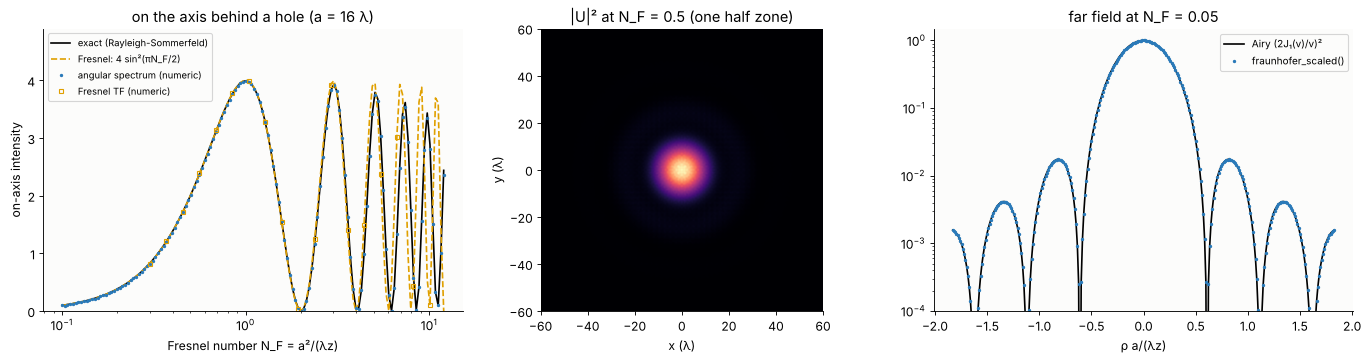

In [8]:
z_far = a**2/(WL*0.05)
xo = np.linspace(-3*0.61*WL*z_far/a, 3*0.61*WL*z_far/a, 301)
U_fh, _, _ = fraunhofer_scaled(hole, x, y, z_far, WL, xo, np.array([0.0]))
U_fh = U_fh[0]
v = k*a*np.abs(xo)/z_far
airy = np.where(v > 0, 2*j1(np.maximum(v, 1e-12))/np.maximum(v, 1e-12), 1.0)
U_an = np.exp(1j*k*z_far)*np.exp(1j*k*xo**2/(2*z_far))/(1j*WL*z_far)*np.pi*a**2*airy
print("Fraunhofer vs. Airy (complex): max |dU| / |U(0)| = {:.1e}".format(
      np.max(np.abs(U_fh - U_an))/np.abs(U_an[150])))
U_rs_far = rayleigh_sommerfeld_I_TF(hole, x, y, a**2/(WL*0.5), WL)[0]

fig, ax = plt.subplots(1, 3, figsize=(17, 4.4), layout="constrained")
ax[0].semilogx(NF, I_exact, color="k", lw=1.5, label="exact (Rayleigh-Sommerfeld)")
ax[0].semilogx(NF, I_fresnel, "--", color=ORANGE, lw=1.5, label="Fresnel: 4 sin²(πN_F/2)")
ax[0].semilogx(NF, np.abs(U_rs)**2, ".", color=BLUE, ms=4, label="angular spectrum (numeric)")
ax[0].semilogx(NF_f, np.abs(U_fr)**2, "s", color=ORANGE, ms=4, mfc="none", label="Fresnel TF (numeric)")
ax[0].set_xlabel("Fresnel number N_F = a²/(λz)")
ax[0].set_ylabel("on-axis intensity")
ax[0].set_title("on the axis behind a hole (a = 16 λ)")
ax[0].legend(fontsize=8.5, loc="upper left")
ax[0].set_ylim(0, 4.9)
ext = (x[0], x[-1], y[0], y[-1])
ax[1].imshow(np.abs(U_rs_far)**2, extent=ext, cmap="magma")
ax[1].set_xlim(-60, 60); ax[1].set_ylim(-60, 60)
ax[1].set_title("|U|² at N_F = 0.5 (one half zone)")
ax[1].set_xlabel("x (λ)"); ax[1].set_ylabel("y (λ)")
ax[2].plot(xo*a/(WL*z_far), np.abs(U_an)**2/np.abs(U_an[150])**2, color="k", lw=1.5, label="Airy (2J₁(v)/v)²")
ax[2].plot(xo*a/(WL*z_far), np.abs(U_fh)**2/np.abs(U_an[150])**2, ".", color=BLUE, ms=4,
           label="fraunhofer_scaled()")
ax[2].set_yscale("log"); ax[2].set_ylim(1e-4, 1.5)
ax[2].set_xlabel("ρ a/(λz)")
ax[2].set_title("far field at N_F = 0.05")
ax[2].legend(fontsize=9)
plt.show()

## 6. The paraxial wave equation and Gaussian beams

Write a beam travelling in +z as a slowly varying envelope times the carrier,
$U = u(x, y, z)\,e^{ikz}$. If $u$ changes little over a wavelength along z,
$\partial_z^2 u$ can be dropped, leaving the **paraxial wave equation**

$$
2ik\,\partial_z u + \nabla_\perp^2 u = 0,
$$

which is the Fresnel integral in differential form. Its fundamental solution
is the Gaussian beam (`beams`, `modes`, `abcd`):

$$
u = \frac{w_0}{w(z)}\exp\!\left(-\frac{r^2}{w^2(z)}\right)
\exp\!\left(+i\frac{k r^2}{2R(z)}\right) e^{-i\psi(z)},
\qquad
w = w_0\sqrt{1 + z^2/z_R^2},\; R = z + z_R^2/z,\; \psi = \arctan(z/z_R),
$$

with $z_R = \pi w_0^2/\lambda$. In the $e^{-i\omega t}$ convention, a
**diverging** wavefront ($z > 0$) has $R > 0$ and a phase that *grows*
outwards, and the **Gouy phase enters with a minus sign**: on the axis, the
phase falls behind the plane wave $e^{ikz}$ by $\psi$, in total by $\pi$
(by $(N + 1)\pi$ for modes of order $N$) from $-\infty$ to $+\infty$. The
complex beam parameter is $q = z + iz_R$, $1/q = 1/R - i\lambda/(\pi w^2)$,
and the field is $\propto e^{ikr^2/(2q)}$.

**Check:** `beams.gauss_laguerre(0, 0, ...)` at the waist, propagated with
the (non-paraxial) angular spectrum to $|z| \le 3z_R$, against the analytic
beam at each plane, and the on-axis phase relative to $e^{ikz}$ against
$-\arctan(z/z_R)$.

max |numeric - analytic| / max |analytic| over -3 z_R ... 3 z_R: 1.1e-03
on-axis phase - k z vs. -arctan(z/z_R): max diff. 3.5e-04 rad
phase across the beam at z = z_R: curvature 1/R = 0.00443 (analytic 1/(2 z_R) = 0.00442): diverging, R > 0


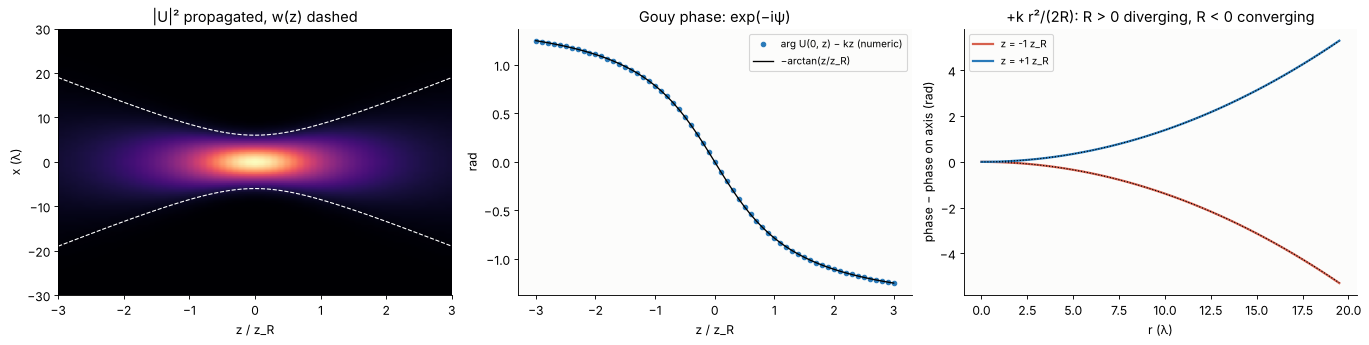

In [9]:
WL, w0 = 1.0, 6.0
k, zR = 2*np.pi/WL, np.pi*w0**2/WL
x, y, X, Y = grid2d(-64, 64, -64, 64, 256)
U0 = beams.gauss_laguerre(0, 0, x, y, 0.0, w0, zR, WL)
zs = np.linspace(-3*zR, 3*zR, 61)
Uz = rayleigh_sommerfeld_I_TF_planes(U0, x, y, zs, WL)[0]
c = 128
err, gouy = [], []
for z, U in zip(zs, Uz):
    A = beams.gauss_laguerre(0, 0, x, y, z, w0, zR, WL)
    err.append(np.max(np.abs(U - A))/np.max(np.abs(A)))
    gouy.append(np.angle(U[c, c]*np.exp(-1j*k*z)))
print("max |numeric - analytic| / max |analytic| over -3 z_R ... 3 z_R: {:.1e}".format(max(err)))
print("on-axis phase - k z vs. -arctan(z/z_R): max diff. {:.1e} rad".format(
      np.max(np.abs(np.array(gouy) + np.arctan(zs/zR)))))
iz = np.argmin(np.abs(zs - zR))
ph = np.unwrap(np.angle(Uz[iz, c, c:c + 40]))
r = x[c:c + 40]
print("phase across the beam at z = z_R: curvature 1/R = {:.5f} (analytic 1/(2 z_R) = {:.5f}): "
      "diverging, R > 0".format(np.polyfit(r**2, ph, 1)[0]*2/k, 1/(2*zR)))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2), layout="constrained")
I_xz = np.abs(Uz[:, c, :])**2
ax[0].imshow(I_xz.T, extent=(zs[0]/zR, zs[-1]/zR, x[0], x[-1]), aspect="auto", cmap="magma")
ax[0].plot(zs/zR, w0*np.sqrt(1 + (zs/zR)**2), color="w", ls="--", lw=1)
ax[0].plot(zs/zR, -w0*np.sqrt(1 + (zs/zR)**2), color="w", ls="--", lw=1)
ax[0].set_ylim(-30, 30)
ax[0].set_xlabel("z / z_R"); ax[0].set_ylabel("x (λ)")
ax[0].set_title("|U|² propagated, w(z) dashed")
ax[1].plot(zs/zR, gouy, "o", color=BLUE, ms=4, label="arg U(0, z) − kz (numeric)")
ax[1].plot(zs/zR, -np.arctan(zs/zR), color="k", lw=1.2, label="−arctan(z/z_R)")
ax[1].set_xlabel("z / z_R"); ax[1].set_ylabel("rad")
ax[1].set_title("Gouy phase: exp(−iψ)")
ax[1].legend(fontsize=9)
for zz_, col in ((-zR, RED), (zR, BLUE)):
    i = np.argmin(np.abs(zs - zz_))
    p = np.unwrap(np.angle(Uz[i, c, c:c + 40]))
    ax[2].plot(r, p - p[0], color=col, lw=2, label="z = {:+.0f} z_R".format(zz_/zR))
    ax[2].plot(r, k*r**2/(2*(zz_ + zR**2/zz_)), "k:", lw=1)
ax[2].set_xlabel("r (λ)"); ax[2].set_ylabel("phase − phase on axis (rad)")
ax[2].set_title("+k r²/(2R): R > 0 diverging, R < 0 converging")
ax[2].legend(fontsize=9)
plt.show()

## 7. Eikonal and rays

For short wavelengths, write the field as an amplitude and a rapidly
varying phase, $U = A(\mathbf r)\,e^{ik_0 S(\mathbf r)}$. Inserting this into
the Helmholtz equation and keeping the highest power of $k_0$ gives the
**eikonal equation**

$$
|\nabla S|^2 = n^2(\mathbf r).
$$

$S$ is the optical path from the source; its level sets are the
**wavefronts**, and the **rays** are their normals, $\nabla S = n\,\hat{\mathbf
s}$, which leads to the ray equation $\frac{d}{ds}\left(n\frac{d\mathbf
r}{ds}\right) = \nabla n$ (`grin`), straight lines with Snell's law at
interfaces in piecewise homogeneous media (`raytrace`), and, for small angles
and heights, the matrices of paraxial optics (`abcd`, `delano`). The phase
of the wave is $k_0 S$: with $e^{-i\omega t}$, **the phase is $+k_0$ times
the optical path**, everywhere in pyoptics.

The sketch below is computed, not drawn by hand: rays from a point source
are refracted into a glass block, and the wavefronts are the points of equal
optical path along them. They are normal to the rays, closer by $1/n$ in
the glass, and no longer spherical there.

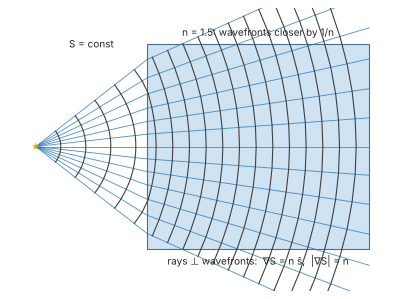

In [10]:
fig, ax = plt.subplots(figsize=(9, 4.6))
sketch.eikonal_wavefronts(ax)
plt.show()

**Rays from a wave field.** The local wave vector of a computed field is the
gradient of its phase, $\mathbf k_\perp = \mathrm{Im}(\nabla_\perp U/U)$, and
the ray slope is $k_x/k_z$. A plane wave through `masks.thin_lens()` (the
transmission $e^{-ikr^2/(2f)}$ of a converging lens with $f > 0$),
propagated with the angular spectrum, must give the slopes $-x/(f - z)$ of
geometric rays towards the focus at $z = +f$.

on-axis maximum at z = 195.4 (f = 200, Fresnel number a^2/(lambda f) = 11.5)
z =  50: ray slopes from the phase gradient vs. -x/(f - z): rms dev. 0.0022, max 0.0058 (slopes up to 0.19; Fresnel number of the rest of the way 9)
z = 100: ray slopes from the phase gradient vs. -x/(f - z): rms dev. 0.0050, max 0.0116 (slopes up to 0.19; Fresnel number of the rest of the way 6)
z = 150: ray slopes from the phase gradient vs. -x/(f - z): rms dev. 0.0136, max 0.0237 (slopes up to 0.19; Fresnel number of the rest of the way 3)


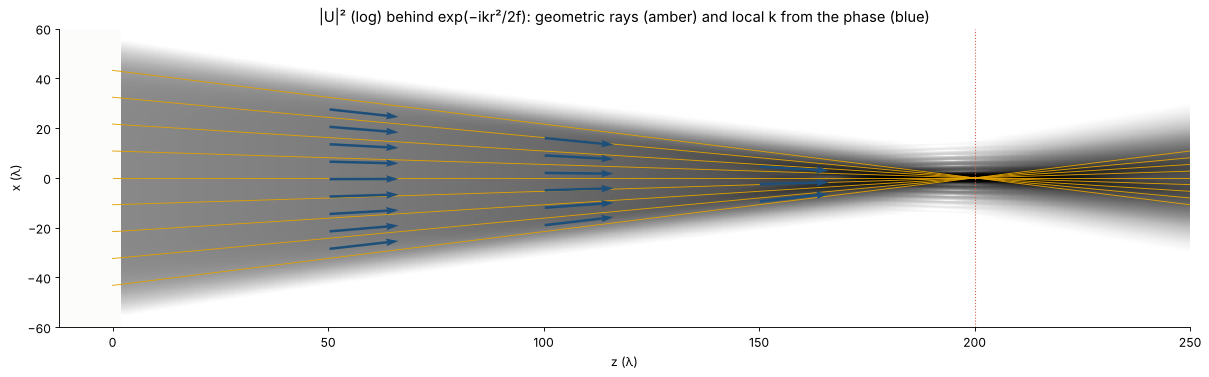

In [11]:
WL, f, a = 1.0, 200.0, 48.0
k = 2*np.pi/WL
x, y, X, Y = grid2d(-128, 128, -128, 128, 512)
dx = x[1] - x[0]
R = np.hypot(X, Y)
pupil = np.exp(-(R/a)**8)                             # super-Gaussian: no sharp edge, no edge waves
U0 = pupil*masks.thin_lens(x, y, f, WL)
zs = np.linspace(2.0, 1.25*f, 160)
Uz = rayleigh_sommerfeld_I_TF_planes(U0, x, y, zs, WL)[0]
c = 256
cut = Uz[:, c, :]                                      # x-z section (y = 0)
I_axis = np.abs(Uz[:, c, c])**2
print("on-axis maximum at z = {:.1f} (f = {:.0f}, Fresnel number a^2/(lambda f) = {:.1f})".format(
      zs[np.argmax(I_axis)], f, a**2/(WL*f)))

quiv = []
for zq in (0.25*f, 0.5*f, 0.75*f):
    i = np.argmin(np.abs(zs - zq))
    U = cut[i]
    kx_loc = np.gradient(np.unwrap(np.angle(U)), dx)
    slope = kx_loc/np.sqrt(k**2 - kx_loc**2)
    inside = np.abs(x) < 0.8*a*(1 - zs[i]/f)
    dev = np.abs(slope[inside] - (-x[inside]/(f - zs[i])))
    quiv.append((zs[i], x[inside][::14], slope[inside][::14]))
    print("z = {:3.0f}: ray slopes from the phase gradient vs. -x/(f - z): rms dev. {:.4f}, max {:.4f} "
          "(slopes up to {:.2f}; Fresnel number of the rest of the way {:.0f})".format(
          zs[i], np.sqrt(np.mean(dev**2)), dev.max(), 0.8*a/f, (a*(1 - zs[i]/f))**2/(WL*(f - zs[i]))))

fig, ax = plt.subplots(figsize=(15, 4.6), layout="constrained")
ax.imshow(np.log10(np.abs(cut.T)**2 + 1e-4), extent=(zs[0], zs[-1], x[0], x[-1]), aspect="auto",
          cmap="Greys", vmin=-3, vmax=2.5)
for x0 in np.linspace(-0.9*a, 0.9*a, 9):
    ax.plot([0, 1.25*f], [x0, x0*(1 - 1.25)], color=ORANGE, lw=0.8)
for zq, xq, sq in quiv:
    ax.quiver(np.full_like(xq, zq), xq, np.ones_like(xq), sq, color="#1d4f7a", angles="xy",
              scale_units="xy", scale=1/16, width=0.0022, zorder=5)
ax.axvline(f, color=RED, ls=":", lw=1)
ax.set_ylim(-60, 60)
ax.set_xlabel("z (λ)"); ax.set_ylabel("x (λ)")
ax.set_title("|U|² (log) behind exp(−ikr²/2f): geometric rays (amber) and local k from the phase (blue)")
plt.show()

The arrows of the wave field lie on the geometric rays. The deviation grows
towards the focus, where the beam narrows to a few Fresnel zones and
diffraction takes over from geometrical optics (with a hard edged aperture,
the edge waves add a further deviation, largest on the axis). The focus lies
at $+f$, not $-f$, slightly shifted towards the lens: the focal shift of a
focus with a finite Fresnel number (Li & Wolf).

### Sign conventions of the ray tracer

Lengths, radii and angles follow one geometric convention in `abcd` and
`raytrace`: z along the optical axis, light entering in +z, y up in the
meridional section (field points at +y), x completing a right handed system
(towards the viewer in the sketches). A radius is positive if the centre of
curvature lies in +z of the vertex (a biconvex lens has $R_1 > 0$, $R_2 <
0$), thicknesses are signed distances from vertex to vertex, ray slopes $u =
dy/dz$ are positive for rays going up (`abcd` uses the reduced angle $nu$),
and a positive field angle means rays that travel upwards. Mirrors are where
the two modules differ: `abcd` unfolds the path (light continues in +z, a
concave mirror has $R > 0$ and acts as a lens with $f = R/2$), `raytrace`
keeps the real geometry (a concave mirror facing the light has $R < 0$, and
thicknesses behind it are negative).

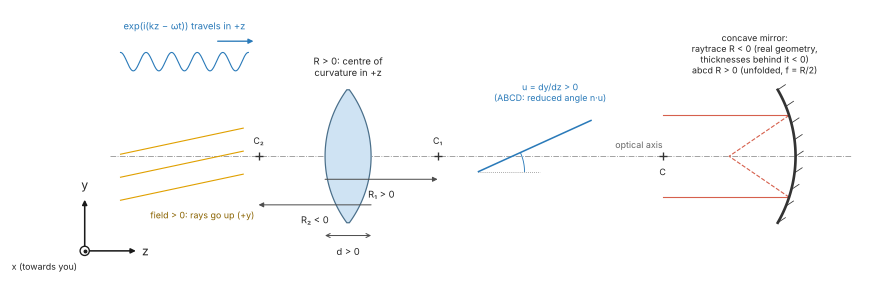

In [12]:
fig, ax = plt.subplots(figsize=(15, 4.4))
sketch.sign_conventions(ax)
plt.show()

### From OPD to pupil phase to PSF: one sign chain

The ray tracer computes the optical path difference on the reference sphere,
$\mathrm{OPD} = \mathrm{OPL}_\mathrm{ray} - \mathrm{OPL}_\mathrm{chief}$, and
hands it to `imaging` as the pupil phase $+2\pi\,\mathrm{OPD}/\lambda$ (a
longer path is a larger phase, section 2). Is this sign consistent with the
propagators? The cleanest test is defocus:

1. `raytrace`: an ideal lens ($f = 50$ mm, NA 0.196) with the image plane
   $\Delta z = 20$ µm *behind* the focus gives $\mathrm{OPD} = \Delta
   z\,(\cos\alpha - 1)$, negative at the rim (the rim of the converging
   wavefront is *ahead* of the reference sphere about the shifted image point).
2. `imaging.get_psf()` with the pupil phase $k\,\Delta z\,(\cos\alpha - 1)$
   must give the field at $\Delta z$ behind the focus...
3. ...which the angular spectrum (`rayleigh_sommerfeld_I_TF()`) computes by
   propagating the in-focus PSF by $+\Delta z$.

raytrace OPD vs. dz (cos a - 1): max diff. 3.1e-04 waves; OPD at the rim -0.776 waves
Fringe Zernike fit: Z4 = -0.3882 waves (image plane behind the focus -> Z4 < 0)
PSF with +2 pi OPD/lambda vs. in-focus PSF propagated by +dz: 1.7e-15
PSF with the opposite sign                          vs. same: 4.4e-01


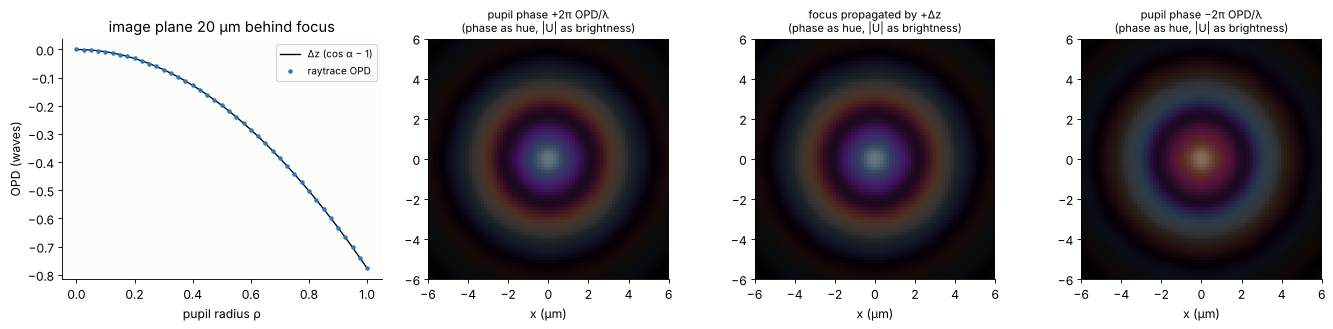

In [13]:
WLmm, f_mm, EPD, dz = 0.5e-3, 50.0, 20.0, 0.02
lens_dz = rt.System([rt.IdealLens(f_mm, f_mm + dz, semi_diameter=EPD/2)], 0, WLmm,
                    entrance_pupil_radius=EPD/2)
rho = np.linspace(0, 1, 41)
opd_rt = lens_dz._opd(lens_dz.trace_pupil(0.0, 0*rho, rho), lens_dz.trace_pupil(0.0))/WLmm
sin_a = rho*(EPD/2)/np.hypot(rho*EPD/2, f_mm)
opd_th = dz*(np.sqrt(1 - sin_a**2) - 1)/WLmm
NA = sin_a[-1]
z_fit = lens_dz.zernike(0.0, 9)
print("raytrace OPD vs. dz (cos a - 1): max diff. {:.1e} waves; OPD at the rim {:+.3f} waves".format(
      np.max(np.abs(opd_rt - opd_th)), opd_rt[-1]))
print("Fringe Zernike fit: Z4 = {:+.4f} waves (image plane behind the focus -> Z4 < 0)".format(z_fit[3]))

WL = 0.5                                                # µm from here on
k = 2*np.pi/WL
dz_um = dz*1e3
x, y, X, Y = grid2d(-20, 20, -20, 20, 256)
defocus = lambda s: (lambda px, py: s*k*dz_um*(np.sqrt(np.clip(1 - NA**2*(px**2 + py**2), 0, None)) - 1))
psf_0 = imaging.get_psf(x, y, NA, k, normalization=None)
psf_plus = imaging.get_psf(x, y, NA, k, phase=defocus(+1), normalization=None)
psf_minus = imaging.get_psf(x, y, NA, k, phase=defocus(-1), normalization=None)
psf_prop = rayleigh_sommerfeld_I_TF(psf_0, x, y, +dz_um, WL)[0]*np.exp(-1j*k*dz_um)
s = np.max(np.abs(psf_0))
print("PSF with +2 pi OPD/lambda vs. in-focus PSF propagated by +dz: {:.1e}".format(
      np.max(np.abs(psf_plus - psf_prop))/s))
print("PSF with the opposite sign                          vs. same: {:.1e}".format(
      np.max(np.abs(psf_minus - psf_prop))/s))

fig, ax = plt.subplots(1, 4, figsize=(17, 4.0), layout="constrained")
ax[0].plot(rho, opd_th, color="k", lw=1.2, label="Δz (cos α − 1)")
ax[0].plot(rho, opd_rt, "o", color=BLUE, ms=3, label="raytrace OPD")
ax[0].set_xlabel("pupil radius ρ"); ax[0].set_ylabel("OPD (waves)")
ax[0].set_title("image plane 20 µm behind focus")
ax[0].legend(fontsize=9)
bright = np.abs(psf_0) > 0.05*s
for a_, P, t in zip(ax[1:], (psf_plus, psf_prop, psf_minus),
                    ("pupil phase +2π OPD/λ", "focus propagated by +Δz", "pupil phase −2π OPD/λ")):
    rgb = plt.cm.twilight((np.angle(P) + np.pi)/(2*np.pi))
    rgb[..., :3] *= np.clip(np.abs(P)/(0.4*s), 0, 1)[..., None]
    a_.imshow(rgb, extent=(x[0], x[-1], y[0], y[-1]))
    a_.set_xlim(-6, 6); a_.set_ylim(-6, 6)
    a_.set_title(t + "\n(phase as hue, |U| as brightness)", fontsize=10); a_.set_xlabel("x (µm)")
plt.show()

The OPD of the ray tracer, the pupil phase of `imaging` and the transfer
function of the angular spectrum agree to rounding error. The opposite sign
gives the field $\Delta z$ *before* the focus, the complex conjugate of the
one behind it: the same intensity, so a sign error in a defocus never shows
in an intensity PSF of a symmetric pupil, only in the phase (or as soon as
other aberrations break the symmetry). In short: **a positive Fringe $Z_4$ (defocus) coefficient means
that the best focus lies behind the plane of evaluation**; moving the image
plane away from the lens makes $Z_4$ negative.

## 8. Interfaces: the Fresnel coefficients and their two sign conventions

At a planar interface, Maxwell's equations reduce to the continuity of the
tangential components of $\mathbf E$ and $\mathbf H$. For s polarization
($\mathbf E$ perpendicular to the plane of incidence) the coefficients are
unambiguous. For p polarization they depend on the reference directions
chosen for the incident, reflected and transmitted $\mathbf E$, and pyoptics
uses **two conventions**:

- `interfaces` (and `mueller.M_reflection_dielectric()`) give ratios of the
  **full field amplitudes** with the reference directions of Hecht and Born
  & Wolf: $r_p = \tan(\varphi_1 - \varphi_2)/\tan(\varphi_1 + \varphi_2)$,
  so that at normal incidence $r_p = (n_2 - n_1)/(n_1 + n_2) = -r_s$.
- `thin_films` (and `coatings`, which the polarization ray trace uses) give
  ratios of the **tangential field components** (characteristic matrix
  method, Macleod, Yeh). There $r_p$ has the opposite sign, $r_p = r_s$ at
  normal incidence, and $t_p$ is the ratio of the tangential fields,
  $t_p^\text{tf} = t_p^\text{int}\cos\varphi_2/\cos\varphi_1$.

Both are correct and the code that combines them converts explicitly
(`raytrace` multiplies `coatings`' $t_p$ by $\cos\varphi_1/\cos\varphi_2$ and
reflects with $-r_p$). The powers $R$ and $T$ are the same. Absorbing media
are $n + i\kappa$ with $\kappa > 0$ in both, and the transmitted normal wave
vector is taken with $\mathrm{Im} \ge 0$, so evanescent and absorbed waves
decay away from the interface.

**Check:** a single layer of zero thickness in `thin_films` is the bare
interface glass ($n = 1.5$) from air:

r_s: interfaces == thin_films: 4.8e-15
r_p: interfaces == -thin_films: 1.1e-14
t_p: interfaces*cos(phi2)/cos(phi1) == thin_films: 1.1e-14
R_p = |r_p|^2 in both; R + T = 1 (interfaces): 5.6e-16
Brewster angle 56.31 deg: r_p = 8.9e-17


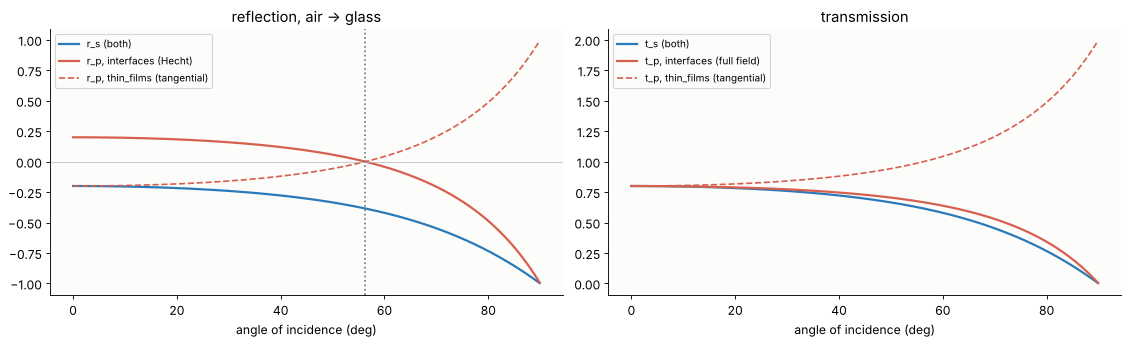

In [14]:
phi = np.radians(np.linspace(0, 89.9, 400))
n1, n2 = 1.0, 1.5
tf = {pol: np.array([thin_films.r_t_coeffs(p, np.array([n2]), np.array([0.0]), np.array([0.0]),
                                           n1, 0.0, n2, 0.0, pol, 1.0) for p in phi])
      for pol in ("s", "p")}
phi2 = interfaces.refracted_angle(phi, n1, n2)
print("r_s: interfaces == thin_films: {:.1e}".format(np.max(np.abs(interfaces.r_s(phi, n1, n2) - tf["s"][:, 0]))))
print("r_p: interfaces == -thin_films: {:.1e}".format(np.max(np.abs(interfaces.r_p(phi, n1, n2) + tf["p"][:, 0]))))
print("t_p: interfaces*cos(phi2)/cos(phi1) == thin_films: {:.1e}".format(
      np.max(np.abs(interfaces.t_p(phi, n1, n2)*np.cos(phi2)/np.cos(phi) - tf["p"][:, 1]))))
print("R_p = |r_p|^2 in both; R + T = 1 (interfaces): {:.1e}".format(
      np.max(np.abs(interfaces.R_p(phi, n1, n2) + interfaces.T_p(phi, n1, n2) - 1))))
print("Brewster angle {:.2f} deg: r_p = {:.1e}".format(
      np.degrees(interfaces.brewster_angle(n1, n2)),
      abs(interfaces.r_p(interfaces.brewster_angle(n1, n2), n1, n2))))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), layout="constrained")
deg = np.degrees(phi)
ax[0].plot(deg, interfaces.r_s(phi, n1, n2), color=BLUE, lw=2, label="r_s (both)")
ax[0].plot(deg, interfaces.r_p(phi, n1, n2), color=RED, lw=2, label="r_p, interfaces (Hecht)")
ax[0].plot(deg, tf["p"][:, 0].real, color=RED, lw=1.5, ls="--", label="r_p, thin_films (tangential)")
ax[0].axvline(np.degrees(interfaces.brewster_angle(n1, n2)), color=GREY, ls=":")
ax[0].axhline(0, color="0.7", lw=0.6)
ax[0].set_xlabel("angle of incidence (deg)")
ax[0].set_title("reflection, air → glass")
ax[0].legend(fontsize=9)
ax[1].plot(deg, interfaces.t_s(phi, n1, n2), color=BLUE, lw=2, label="t_s (both)")
ax[1].plot(deg, interfaces.t_p(phi, n1, n2), color=RED, lw=2, label="t_p, interfaces (full field)")
ax[1].plot(deg, tf["p"][:, 1].real, color=RED, lw=1.5, ls="--", label="t_p, thin_films (tangential)")
ax[1].set_xlabel("angle of incidence (deg)")
ax[1].set_title("transmission")
ax[1].legend(fontsize=9)
plt.show()

## 9. Polarization: Jones vectors and handedness

For a plane wave (or a ray, or a paraxial beam), only the two transverse
components matter. pyoptics writes them as the **Jones vector** $[E_x,
E_y]$, a 2 × 2 **Jones matrix** maps it through an element, and the
**Stokes vector** $S = (S_0, S_1, S_2, S_3)$ describes partially polarized
light, with

$$
S_0 = |E_x|^2 + |E_y|^2,\quad S_1 = |E_x|^2 - |E_y|^2,\quad
S_2 = 2\,\mathrm{Re}(E_x^* E_y),\quad S_3 = 2\,\mathrm{Im}(E_x^* E_y).
$$

**Which way does $[1, i]$ turn?** With $e^{-i\omega t}$, at a fixed
position, $\mathrm{Re}\{[1, i]\,e^{-i\omega t}\} = (\cos\omega t,
\sin\omega t)$: the field turns from $+x$ to $+y$, counterclockwise for an
observer who looks towards the source (the beam comes towards the viewer, x
to the right, y up). Its spin points along $+z$ (positive helicity) and
$S_3 = +1$. pyoptics calls it **right-handed**, `jones.J_RHCP` and
`mueller.S_RCP`: right-handed about the direction of propagation (IEEE
convention, also `tweezers` with `"right"`). The traditional optics naming
(Born & Wolf, Hecht) calls the same field *left*-circular, because it looks
at the sense of rotation from the observer's side. In space, at a fixed
time, $\mathrm{Re}\{[1, i]\,e^{ikz}\} = (\cos kz, -\sin kz)$ is a helix.

**Elements.** `jones.J_WP(delta, phi)` is a retarder with the fast axis
along x before rotation: the slow y component gets the extra phase
$e^{+i\delta}$, i.e. it is delayed (section 2). An element rotated by
$\phi$ (counterclockwise from +x towards +y) is `jones.rotate(J, phi)`
$= R(\phi)^T J R(\phi)$.

S(J_RHCP) = [1. 0. 0. 1.]   S(J_LHCP) = [ 1.  0.  0. -1.]
quarter wave plate (fast axis x) on +45 deg linear: [0.707+0.j    0.   +0.707j] -> S_3 = +1.000 (right-handed)
polarizer rotated by +30 deg passes the direction [0.866 0.5  ] (cos 30, sin 30 = 0.866, 0.500)
Malus: |P(theta) e_x|^2 - cos^2(theta): 2.2e-16
Jones and Mueller agree: M_from_jones(QWP) S_45 = [1. 0. 0. 1.]


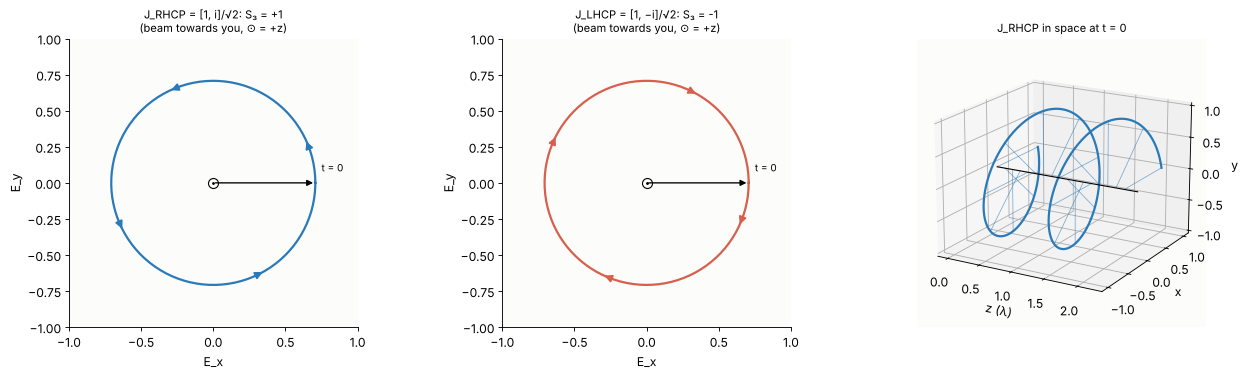

In [15]:
print("S(J_RHCP) =", mueller.stokes_from_complex_E(jones.J_RHCP), "  S(J_LHCP) =",
      mueller.stokes_from_complex_E(jones.J_LHCP))
lin45 = np.array([1.0, 1.0])/np.sqrt(2)
out = jones.J_QWP @ lin45
print("quarter wave plate (fast axis x) on +45 deg linear: {} -> S_3 = {:+.3f} (right-handed)".format(
      np.round(out, 3), mueller.stokes_from_complex_E(out)[3]))
P30 = jones.rotate(jones.J_polarizer(1, 0), np.radians(30))
print("polarizer rotated by +30 deg passes the direction {} (cos 30, sin 30 = {:.3f}, {:.3f})".format(
      np.round(P30 @ np.array([np.cos(np.radians(30)), np.sin(np.radians(30))]), 3),
      np.cos(np.radians(30)), np.sin(np.radians(30))))
th = np.radians(np.linspace(0, 90, 7))
malus = [np.linalg.norm(jones.rotate(jones.J_polarizer(1, 0), t) @ np.array([1.0, 0.0]))**2 for t in th]
print("Malus: |P(theta) e_x|^2 - cos^2(theta): {:.1e}".format(np.max(np.abs(np.array(malus) - np.cos(th)**2))))
print("Jones and Mueller agree: M_from_jones(QWP) S_45 = {}".format(
      np.round(mueller.M_from_jones(jones.J_QWP) @ mueller.stokes_from_complex_E(lin45), 3)))

wt = np.linspace(0, 2*np.pi, 200)
fig = plt.figure(figsize=(16, 4.6), layout="constrained")
for i, (J, name, col) in enumerate(((jones.J_RHCP, "J_RHCP = [1, i]/√2", BLUE),
                                    (jones.J_LHCP, "J_LHCP = [1, −i]/√2", RED))):
    a = fig.add_subplot(1, 3, i + 1)
    e = np.real(J[:, None]*np.exp(-1j*wt))
    a.plot(e[0], e[1], color=col, lw=2)
    for tt in (0.3, 1.9, 3.5, 5.1):
        j_ = np.argmin(np.abs(wt - tt))
        a.annotate("", xy=(e[0, j_ + 4], e[1, j_ + 4]), xytext=(e[0, j_], e[1, j_]),
                   arrowprops=dict(arrowstyle="-|>", color=col, lw=1.5, mutation_scale=14))
    a.annotate("", xy=(e[0, 0], e[1, 0]), xytext=(0, 0),
               arrowprops=dict(arrowstyle="-|>", color="k", lw=1.2))
    a.text(0.75, 0.08, "t = 0", fontsize=9)
    a.plot(0, 0, "o", ms=9, mfc="white", mec="k"); a.plot(0, 0, "k.", ms=3)
    a.set_aspect("equal"); a.set_xlim(-1, 1); a.set_ylim(-1, 1)
    a.set_xlabel("E_x"); a.set_ylabel("E_y")
    a.set_title("{}: S₃ = {:+.0f}\n(beam towards you, ⊙ = +z)".format(
        name, mueller.stokes_from_complex_E(J)[3]), fontsize=10)
a3 = fig.add_subplot(1, 3, 3, projection="3d")
zz = np.linspace(0, 2, 300)
E = np.real(jones.J_RHCP[:, None]*np.exp(1j*2*np.pi*zz))*np.sqrt(2)
a3.plot(zz, E[0], E[1], color=BLUE, lw=2)
for zi in np.linspace(0, 2, 17):
    ei = np.real(jones.J_RHCP*np.exp(1j*2*np.pi*zi))*np.sqrt(2)
    a3.plot([zi, zi], [0, ei[0]], [0, ei[1]], color=BLUE, lw=0.7, alpha=0.6)
a3.plot([0, 2.2], [0, 0], [0, 0], "k-", lw=1)
a3.set_xlabel("z (λ)"); a3.set_ylabel("x"); a3.set_zlabel("y")
a3.set_title("J_RHCP in space at t = 0", fontsize=10)
a3.view_init(elev=18, azim=-60)
plt.show()

## 10. Pupils and Zernike polynomials

`imaging` samples the pupil on the frequency grid of the image plane and
uses **normalized pupil coordinates** $(P_x, P_y) = (k_x, k_y)/(k\,
\mathrm{NA})$, so that the pupil is the unit disk; `raytrace` uses the same
unit disk in its entrance pupil (with ray aiming: the stop). Polar
coordinates are $\rho = |P|$ and the **azimuth $\varphi$ is measured from
$+x$ towards $+y$** (`arctan2(P_y, P_x)`). The pupil function is
$P = A\,e^{i\Phi}$ with the phase $\Phi = 2\pi W$ for a wavefront error $W$
in waves, and $W$ is the ray tracer's OPD (section 7).

Aberrations are expanded in **Fringe Zernike polynomials** (`bases`,
`raytrace.System.zernike()`, `litho`): the University of Arizona ordering,
by $n + |m|$, cosine terms ($m > 0$) before sine terms ($m < 0$), and **not
normalized**: every term is 1 at the rim for $\varphi = 0$ (or 90°/m for
the sine terms), $Z_j = R_n^{|m|}(\rho)\,\{\cos, \sin\}(|m|\varphi)$. Their
mean square over the disk is $(1 + \delta_{m0})/(2(n + 1))$
(`fringe_zernike_norm()` gives $\pi$ times that), so a coefficient $c_j$
contributes the rms $c_j\sqrt{(1 + \delta_{m0})/(2(n+1))}$. Noll's
ordering (common in astronomy and many papers) differs in both indexing and
normalization, see the table below.

bases.fringe_zernike() vs. the textbook Fringe formulas, Z1..Z16: max diff. 8.4e-15
mean square of Z5 over the disk: 0.1653 (1/6 = 0.1667); of Z9: 0.1988 (1/5)


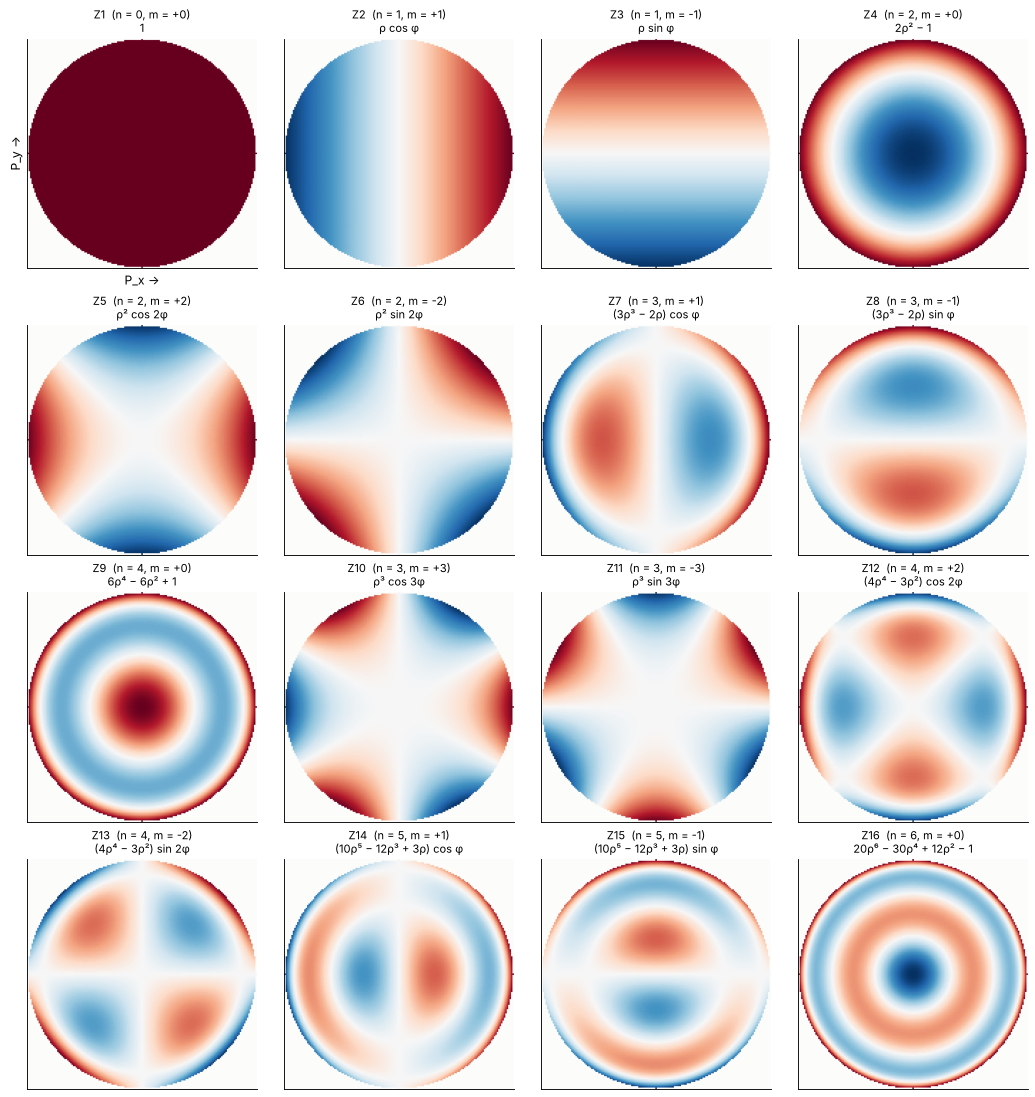

In [16]:
xs = np.linspace(-1, 1, 161)
PX, PY = np.meshgrid(xs, xs)
RHO, PHI = np.hypot(PX, PY), np.arctan2(PY, PX)
disk = RHO <= 1
formulas = {1: (lambda r, p: 1 + 0*r, "1"), 2: (lambda r, p: r*np.cos(p), "ρ cos φ"),
            3: (lambda r, p: r*np.sin(p), "ρ sin φ"), 4: (lambda r, p: 2*r**2 - 1, "2ρ² − 1"),
            5: (lambda r, p: r**2*np.cos(2*p), "ρ² cos 2φ"), 6: (lambda r, p: r**2*np.sin(2*p), "ρ² sin 2φ"),
            7: (lambda r, p: (3*r**3 - 2*r)*np.cos(p), "(3ρ³ − 2ρ) cos φ"),
            8: (lambda r, p: (3*r**3 - 2*r)*np.sin(p), "(3ρ³ − 2ρ) sin φ"),
            9: (lambda r, p: 6*r**4 - 6*r**2 + 1, "6ρ⁴ − 6ρ² + 1"),
            10: (lambda r, p: r**3*np.cos(3*p), "ρ³ cos 3φ"), 11: (lambda r, p: r**3*np.sin(3*p), "ρ³ sin 3φ"),
            12: (lambda r, p: (4*r**4 - 3*r**2)*np.cos(2*p), "(4ρ⁴ − 3ρ²) cos 2φ"),
            13: (lambda r, p: (4*r**4 - 3*r**2)*np.sin(2*p), "(4ρ⁴ − 3ρ²) sin 2φ"),
            14: (lambda r, p: (10*r**5 - 12*r**3 + 3*r)*np.cos(p), "(10ρ⁵ − 12ρ³ + 3ρ) cos φ"),
            15: (lambda r, p: (10*r**5 - 12*r**3 + 3*r)*np.sin(p), "(10ρ⁵ − 12ρ³ + 3ρ) sin φ"),
            16: (lambda r, p: 20*r**6 - 30*r**4 + 12*r**2 - 1, "20ρ⁶ − 30ρ⁴ + 12ρ² − 1")}
dev = max(np.max(np.abs(fringe_zernike(j, PX[disk], PY[disk]) - fn(RHO[disk], PHI[disk])))
          for j, (fn, _) in formulas.items())
print("bases.fringe_zernike() vs. the textbook Fringe formulas, Z1..Z16: max diff. {:.1e}".format(dev))
dA = (xs[1] - xs[0])**2
print("mean square of Z5 over the disk: {:.4f} (1/6 = {:.4f}); of Z9: {:.4f} (1/5)".format(
      np.sum(fringe_zernike(5, PX, PY)[disk]**2)*dA/np.pi, 1/6,
      np.sum(fringe_zernike(9, PX, PY)[disk]**2)*dA/np.pi))

fig, axs = plt.subplots(4, 4, figsize=(13, 13.6), layout="constrained")
for j, a in zip(range(1, 17), axs.flat):
    Z = np.where(disk, fringe_zernike(j, PX, PY), np.nan)
    a.imshow(Z, extent=(-1, 1, -1, 1), cmap="RdBu_r", vmin=-1, vmax=1)
    n, m = fringe_to_n_m(j)
    a.set_title("Z{}  (n = {}, m = {:+d})\n{}".format(j, n, m, formulas[j][1]), fontsize=10)
    a.set_xticks([]); a.set_yticks([])
axs[0, 0].set_xlabel("P_x →"); axs[0, 0].set_ylabel("P_y →")
plt.show()

The colour scale is the same for all terms (red +1, blue −1); $y$ (and
$P_y$) point up in all images.

| Fringe | Noll | aberration | Fringe term | Noll term |
|---|---|---|---|---|
| Z1 | Z1 | piston | 1 | 1 |
| Z2 | Z2 | tilt about y (x tilt) | ρ cos φ | 2 ρ cos φ |
| Z3 | Z3 | tilt about x (y tilt) | ρ sin φ | 2 ρ sin φ |
| Z4 | Z4 | defocus | 2ρ² − 1 | √3 (2ρ² − 1) |
| Z5 | Z6 | astigmatism 0°/90° | ρ² cos 2φ | √6 ρ² cos 2φ |
| Z6 | Z5 | astigmatism ±45° | ρ² sin 2φ | √6 ρ² sin 2φ |
| Z7 | Z8 | coma along x | (3ρ³ − 2ρ) cos φ | √8 (3ρ³ − 2ρ) cos φ |
| Z8 | Z7 | coma along y | (3ρ³ − 2ρ) sin φ | √8 (3ρ³ − 2ρ) sin φ |
| Z9 | Z11 | primary spherical | 6ρ⁴ − 6ρ² + 1 | √5 (6ρ⁴ − 6ρ² + 1) |
| Z10 | Z10 | trefoil 0° | ρ³ cos 3φ | √8 ρ³ cos 3φ |
| Z11 | Z9 | trefoil 30° | ρ³ sin 3φ | √8 ρ³ sin 3φ |

**Signs and the two kinds of pupil coordinates.** The pupil of `imaging` is
the angular spectrum of the image: $P$ is the *direction* of a plane wave in
the image space. A positive $Z_2$ adds the phase $2\pi c\,P_x$, i.e. it
delays the plane waves that travel towards $+x$, and the image point, where
all plane waves are in phase, moves to $x = -\partial\Phi/\partial k_x =
-c\lambda/\mathrm{NA}$. A positive $Z_4$ puts the best focus **behind** the
plane of evaluation (section 7).

`raytrace.System.opd()` and `System.zernike()`, however, use *positions* in
the entrance pupil. Behind a lens that forms a real image, a ray through the
top of the pupil travels downwards, so the two coordinate systems are
point-mirrored, and all Zernikes that are odd in $\varphi$ ($Z_2$, $Z_3$,
$Z_7$, $Z_8$, $Z_{10}$, $Z_{11}$, ...) **change sign** between them.
`System.pupil()` (and `System.psf()`), as well as
`litho.lens.lens_aberrations()`, map the OPD onto the direction coordinates
before handing it to `imaging` or `litho`; coefficients from
`System.zernike()` must not be passed to `imaging` directly. Since field
points lie at $+y$, the coma of an off-axis field of a centred system
appears in $Z_8$ (along y), not in $Z_7$, in both.

In [17]:
WL, NA = 0.5, 0.25
k = 2*np.pi/WL
x, y, X, Y = grid2d(-12, 12, -12, 12, 256)
psf = imaging.get_psf(x, y, NA, k, phase=lambda px, py: 2*np.pi*0.5*fringe_zernike(2, px, py))
I = np.abs(psf)**2
xc = np.sum(I*X)/np.sum(I)
print("Z2 = +0.5 waves in the imaging pupil: PSF centroid at x = {:+.4f} µm; "
      "stationary phase: -c lambda/NA = {:+.4f} µm".format(xc, -0.5*WL/NA))

field = np.radians(5.0)
singlet = rt.System([rt.Surface(51.68, 4.0, n_after=1.5168, semi_diameter=12.0),
                     rt.Surface(np.inf, 96.0, n_after=1.0, semi_diameter=12.0)], 0, 0.55e-3,
                    field_angle=field, entrance_pupil_radius=8.0).at_paraxial_focus()
z_ep = singlet.zernike(field, 16)                       # entrance pupil positions
pup = singlet.pupil(field, 64)                          # imaging coordinates (directions)
ps = np.linspace(-1, 1, 81)
QX, QY = np.meshgrid(ps, ps)
ok = QX**2 + QY**2 <= 0.98
A = np.column_stack([fringe_zernike(j, QX[ok], QY[ok]) for j in range(1, 17)])
z_dir = np.linalg.lstsq(A, pup.phase(QX[ok], QY[ok])/(2*np.pi), rcond=None)[0]
print("plano-convex singlet, field 5 deg at +y (waves):")
for j, name in ((5, "astigmatism"), (7, "coma x"), (8, "coma y"), (9, "spherical")):
    print("  Z{:<2d} {:12s} System.zernike(): {:+.3f}   fit on System.pupil(): {:+.3f}".format(
          j, name, z_ep[j - 1], z_dir[j - 1]))

Z2 = +0.5 waves in the imaging pupil: PSF centroid at x = -0.9728 µm; stationary phase: -c lambda/NA = -1.0000 µm
plano-convex singlet, field 5 deg at +y (waves):
  Z5  astigmatism  System.zernike(): +2.178   fit on System.pupil(): +2.112
  Z7  coma x       System.zernike(): +0.000   fit on System.pupil(): +0.000
  Z8  coma y       System.zernike(): -0.399   fit on System.pupil(): +0.578
  Z9  spherical    System.zernike(): -0.350   fit on System.pupil(): -0.155


## 11. Arrays, axes and units

**Array layout.** The wave optics modules (`propagators`, `imaging`, `beams`,
`masks`, `wpm`, `tilted`, `bases`, ...) sample fields on meshgrids from
`utils.grid2d()`: `X, Y = np.meshgrid(x, y)`, so arrays are indexed `[y,
x]` (rows are y, columns are x). The notebooks plot them with `imshow(...,
origin="lower", extent=(x[0], x[-1], y[0], y[-1]))`, so that +y is up. The
FDTD and FDFD index their fields `[x, y]` (`[x, y, z]` in 3D,
`fdtd.Grid.shape` is `(n_x, n_y)`), and are plotted with `.T`.

**Units.** The physics does not care, but the modules do:

| module | lengths | wavelength | angles |
|---|---|---|---|
| `propagators`, `imaging`, `beams`, `masks`, `wpm`, `tilted`, `abcd`, `thin_films`, `interfaces` | any unit, the same for all lengths and the wavelength | vacuum wavelength in that unit (`propagators` take the medium index `n` separately) | radians |
| `raytrace`, `lens_optimization`, `tolerancing` | `System(units="mm")` by default | in the system's unit (dispersion is evaluated in nm internally) | radians (field angles, tilts) |
| `materials`, `glasses`, `coatings` dispersion | | **nm** for `n(wavelength_nm)` | |
| `fdtd`, `fdfd` | normalized: c = ε₀ = μ₀ = 1, any length unit | in the length unit; ω = 2π/λ | radians |
| `litho` | nm (simulation); the ray traced lenses of `litho.lens` in mm | nm | radians, but degrees for pole azimuths/openings of `Illumination` and the absorber phase of masks |
| `ultrafast` | mm | nm; times in fs, ω in rad/fs | radians |

Wavelengths passed to the wave optics functions are **vacuum** wavelengths
together with the index `n` of the medium (the wavelength in the medium is
λ/n), except where a docstring says otherwise.

## 12. Cheat sheet

| quantity | pyoptics convention |
|---|---|
| time dependence | $e^{-i\omega t}$, implicit; fields $\propto e^{i(\mathbf k\cdot\mathbf r - \omega t)}$ |
| propagation by $z > 0$ | multiplies plane waves by $e^{+ik_z z}$; $k_z$ with $\mathrm{Im}\,k_z \ge 0$ |
| spherical wave | $e^{+ikr}/r$ outgoing, $e^{-ikr}/r$ converging |
| absorbing medium | $n + i\kappa$, $\kappa > 0$ |
| phase and path | phase $= +k_0\cdot$ optical path; positive phase = delay |
| spatial FT | `FT()`: kernel $e^{-i\mathbf k\cdot\mathbf r}$, centred arrays, unnormalized (`*dx*dy` → integral); `inv_FT()`: $e^{+i\mathbf k\cdot\mathbf r}/N$ |
| temporal FT (`ultrafast`, FDTD DFT) | $E(t) = \sum E(\omega)e^{-i\omega t}$; $F(\omega) = \sum f(t)e^{+i\omega t}\Delta t$ |
| frequencies | `utils.frequencies()`: angular wavenumbers $k = 2\pi f$ by default |
| Gaussian beam | phase $kz + kr^2/(2R) - \psi$, $R > 0$ diverging, Gouy $e^{-i\psi}$, $q = z + iz_R$ |
| thin lens | $e^{-ikr^2/(2f)}$, $f > 0$ converging |
| axes | z optical axis, light enters in +z; y up (meridional plane, field at +y); x towards the viewer |
| radii | $R > 0$ if the centre of curvature lies in +z (`abcd` and `raytrace`) |
| mirrors | `abcd`: unfolded, concave $R > 0$; `raytrace`: real geometry, concave $R < 0$, thicknesses behind it $< 0$ |
| ray slopes, field | $u = dy/dz > 0$ upwards (`abcd`: reduced angle $nu$); field $> 0$: rays travel upwards |
| tilts (`raytrace`) | $R_x(a_x)R_y(a_y)R_z(a_z)$, counterclockwise, after the decentre |
| OPD and pupil phase | $\mathrm{OPD} = \mathrm{OPL}_\text{ray} - \mathrm{OPL}_\text{chief}$; pupil phase $+2\pi\,\mathrm{OPD}/\lambda$; image plane behind focus → $Z_4 < 0$ |
| pupil coordinates | `imaging`, `litho`, `System.pupil()`: directions, $(P_x, P_y) = \mathbf k_\perp/(k\,\mathrm{NA})$; `System.opd()`, `System.zernike()`: entrance pupil positions (point-mirrored for a real image); unit disk, $\varphi$ from +x towards +y |
| Zernikes | Fringe ordering, unnormalized (1 at the rim); positive $Z_2$ in `imaging` moves the image to $-x$ |
| Fresnel coefficients | `interfaces`: full fields, Hecht ($r_p = -r_s$ at normal incidence); `thin_films`/`coatings`: tangential fields ($r_p = r_s$) |
| Jones vectors | $[E_x, E_y]$; $[1, i]/\sqrt2$ = `J_RHCP`: turns x → y, $S_3 = +1$, positive helicity (IEEE right, Born & Wolf left) |
| wave plates | fast axis along x before rotation; slow component $\times e^{+i\delta}$; rotated element $R(\phi)^T J R(\phi)$ |
| FDTD 2D modes | `"Ez"`: E out of plane (TM in the FDTD literature, TE/s for gratings and scattering); `"Hz"`: H out of plane |
| arrays | wave optics `[y, x]`; FDTD/FDFD `[x, y(, z)]` |

## 13. Inconsistencies found while writing this notebook

Going through the code for the conventions turned up these points. None of
them is a bug in the numerics of a module; they are places where a user
combining modules can trip.

1. **Fresnel coefficients for p polarization.** `interfaces` (Hecht, full
   fields) and `thin_films`/`coatings` (tangential fields) differ in the sign
   of $r_p$ and in $t_p$ by $\cos\varphi_2/\cos\varphi_1$ (section 8). The
   ray tracer converts correctly, but the `thin_films` docstring does not
   say which convention it uses. *Fixed in the docstring and on the
   conventions page.*
2. **"A positive phase runs ahead."** The docstrings of `imaging` and
   `interferometry` said that a positive pupil phase (or $\varphi = kW$)
   corresponds to a wavefront that *runs ahead*. With $e^{-i\omega t}$ a
   positive phase is a *delay* (section 2), consistent with the ray
   tracer's $+2\pi\,\mathrm{OPD}/\lambda$ and with the defocus check of
   section 7, where the rim of the wavefront that is ahead of the reference
   sphere has a negative OPD. The formulas in both modules are right; only
   the wording was reversed. *Fixed in the docstrings.*
3. **Mirror radii.** Concave mirrors have $R > 0$ in `abcd` (unfolded) and
   $R < 0$ in `raytrace` (real geometry). Documented in both modules and on
   the conventions page, but easy to miss when moving a resonator from one
   to the other.
4. **Array order.** Wave optics arrays are `[y, x]`, FDTD/FDFD arrays
   `[x, y]`. Not stated on the conventions page so far. *Added there.*
5. **Two kinds of pupil coordinates.** `raytrace.System.opd()` and
   `System.zernike()` use positions in the entrance pupil, `imaging`, `litho`
   and `System.pupil()` the directions of the image space plane waves. For
   a lens that forms a real image they are point-mirrored, and the
   Zernikes odd in φ change sign (section 10: $Z_8$ of the singlet is
   −0.40 waves in one and +0.58 waves in the other; the magnitudes differ
   too, because the mapping between the two is not linear and the tilt is
   referenced differently). The conversion is done correctly inside
   `System.pupil()`, `System.psf()` and `litho.lens`, but neither
   `System.zernike()` nor `imaging` warned about it. *Notes added to both
   docstrings and to the conventions page.*
6. **Angles in degrees** in `litho.illumination` (pole azimuths and
   openings) and `litho.mask` (absorber phase), radians everywhere else.
7. **Small things:** `beams.gauss_laguerre()`/`gauss_hermite()` use the
   vacuum wavenumber (a `TODO: n dependency` in the code) and take $z_R$ as
   an independent argument, so a $z_R$ inconsistent with $w_0$ and λ is
   silently accepted; `propagators.rayleigh_sommerfeld_I_DI()` carries a
   `TODO: two pi?` next to its kernel, which is correct as it stands
   ($\frac{1}{2\pi}\frac{z}{r}(\frac{1}{r} - ik)\frac{e^{ikr}}{r}$, the
   formula of section 5).

In [18]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 21 s


## Summary

- pyoptics solves Maxwell's equations on several levels: rigorously in time
  (`fdtd`) and frequency (`fdfd`, `litho.rcwa`, Mie series); in the scalar
  Helmholtz approximation (`wpm`); exactly in homogeneous media by the
  angular spectrum (= Rayleigh-Sommerfeld I, `propagators`); paraxially
  (Fresnel, Gaussian beams, `beams`, `modes`); in the far field (Fraunhofer,
  `imaging`); and in the ray limit (`raytrace`, `grin`, `abcd`), with exact
  side branches for planar layers (`interfaces`, `thin_films`) and
  polarization (`polarization`).
- One time convention, $e^{-i\omega t}$, fixes all other signs: waves grow in
  phase as they travel ($e^{+ikz}$, checked in the FDTD to $10^{-3}$),
  outgoing waves are $e^{+ikr}/r$, absorption is $n + i\kappa$, a positive
  phase is a delay, the spatial FT has the kernel $e^{-i\mathbf
  k\cdot\mathbf r}$ (checked against the analytic Gaussian), the Gouy phase
  enters as $e^{-i\psi}$ (checked to $10^{-3}$ rad), $[1, i]$ turns from x
  to y ($S_3 = +1$).
- The diffraction integrals agree with the exact on-axis field of a hole
  and with the Airy pattern; the Fresnel approximation fails visibly once
  the hole holds more than a few zones.
- Rays are the normals of the wavefronts: the phase gradient of a computed
  focus reproduces the geometric ray slopes. The OPD of the ray tracer, the
  pupil phase of `imaging` and the transfer function of the angular spectrum
  close to rounding error, which fixes the signs of defocus and Zernikes.
- Inconsistencies found: two conventions for $r_p$, $t_p$ (now documented),
  reversed wording "positive phase runs ahead" (fixed), entrance pupil vs.
  direction coordinates of the pupil (odd Zernikes change sign between
  `System.zernike()` and `imaging`), mirror radii in `abcd` vs.
  `raytrace`, array order `[y, x]` vs. `[x, y]`, degrees in parts of
  `litho`.

## References

- M. Born and E. Wolf, "Principles of Optics", 7th ed., Cambridge University Press (1999), chapters 1 (Maxwell's equations, Fresnel formulas), 3 (eikonal and rays), 8 (diffraction) and 9 (aberrations, Zernike polynomials).
- J. D. Jackson, "Classical Electrodynamics", 3rd ed., Wiley (1999), chapters 7 and 10.
- J. W. Goodman, "Introduction to Fourier Optics", 4th ed., W. H. Freeman (2017), chapters 3 and 4 (Rayleigh-Sommerfeld, angular spectrum, Fresnel and Fraunhofer).
- A. Zangwill, "Modern Electrodynamics", Cambridge University Press (2013), chapter 17 (time harmonic fields, interfaces).
- E. Hecht, "Optics", 5th ed., Pearson (2017), section 4.6 (Fresnel equations and their sign conventions) and chapter 8 (polarization).
- H. A. Macleod, "Thin-Film Optical Filters", 3rd ed., Institute of Physics Publishing (2001), chapter 2 (characteristic matrices).
- P. Yeh, "Optical Waves in Layered Media", Wiley (1988).
- A. E. Siegman, "Lasers", University Science Books (1986), chapters 16 and 17 (paraxial wave equation, Gaussian beams).
- H. Kogelnik and T. Li, "Laser beams and resonators", Appl. Opt. 5, 1550-1567 (1966).
- W. T. Welford, "Aberrations of Optical Systems", Adam Hilger (1986) (OPD, reference sphere, sign conventions).
- R. Kingslake and R. B. Johnson, "Lens Design Fundamentals", 2nd ed., Academic Press (2010).
- E. Wolf and E. W. Marchand, "Comparison of the Kirchhoff and the Rayleigh-Sommerfeld theories of diffraction at an aperture", J. Opt. Soc. Am. 54, 587-594 (1964).
- K. Matsushima and T. Shimobaba, "Band-limited angular spectrum method for numerical simulation of free-space propagation in far and near fields", Opt. Express 17, 19662-19673 (2009).
- Y. Li and E. Wolf, "Focal shifts in diffracted converging spherical waves", Opt. Commun. 39, 211-215 (1981).
- R. J. Noll, "Zernike polynomials and atmospheric turbulence", J. Opt. Soc. Am. 66, 207-211 (1976).
- J. C. Wyant and K. Creath, "Basic wavefront aberration theory for optical metrology", in Applied Optics and Optical Engineering, Vol. XI, Academic Press (1992).
- R. C. Jones, "A new calculus for the treatment of optical systems. I. Description and discussion of the calculus", J. Opt. Soc. Am. 31, 488-493 (1941).
- R. A. Chipman, W.-S. T. Lam and G. Young, "Polarized Light and Optical Systems", CRC Press (2018), chapters 2 and 9 (handedness conventions, polarization ray tracing).
- IEEE Std 149-1979, "IEEE Standard Test Procedures for Antennas" (definition of right-hand circular polarization).
- A. Taflove and S. C. Hagness, "Computational Electrodynamics: The Finite-Difference Time-Domain Method", 3rd ed., Artech House (2005).